In [ ]:

########### PRACTICAL 1A #########

import pandas as pd
import numpy as np

# STEP 1: Create a small dirty CSV file
dirty_rows = """name,age,city,salary,joining_date
 amit shah ,28,mumbai,45000,2021-03-15
PRIYA NAIR,34,Pune,52000,2020-07-01
rahul verma,,MUMBAI,48000,2019-11-23
Sneha Iyer,29,pune ,,2022-01-10
karan mehta,41,Mumbai,950000,2018-05-30
Neha Joshi,,Nagpur,39000,2021-09-12
priya nair,34,Pune,52000,2020-07-01
Vijay Kulkarni,52,nagpur,61000,2017-02-28
Anita Desai,31,,47000,2020-12-05
Rohan Patil,26,Mumbai,41000,2022-06-18
"""

with open("employees_dirty.csv", "w") as f:
    f.write(dirty_rows)

# STEP 2: Load the CSV file and display the data
df = pd.read_csv("employees_dirty.csv")

print("---- First look at the raw data ----")
print(df)

print("\nShape (rows, columns):", df.shape)
print("\nData types:\n", df.dtypes)

# STEP 3: Find missing values
print("\n---- Missing values per column ----")
print(df.isnull().sum())

# STEP 4: Fix inconsistent formatting
df["name"] = df["name"].str.strip()
df["name"] = df["name"].str.title()

df["city"] = df["city"].str.strip().str.title()

df["joining_date"] = pd.to_datetime(df["joining_date"])

# STEP 5: Remove duplicate rows
before = len(df)
df = df.drop_duplicates()

print("\nDuplicate rows removed:", before - len(df))

# STEP 6: Handle missing values
# Numeric columns: fill missing values with median
df["age"] = df["age"].fillna(df["age"].median())
df["salary"] = df["salary"].fillna(df["salary"].median())

# Text column: fill missing city with the most frequent city
df["city"] = df["city"].fillna(df["city"].mode()[0])

print("\nMissing values after cleaning:\n", df.isnull().sum())

# STEP 7: Detect salary outliers using the IQR rule
q1 = df["salary"].quantile(0.25)
q3 = df["salary"].quantile(0.75)

iqr = q3 - q1

lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr

print("\nSalary fences: lower = %.0f, upper = %.0f" % (lower, upper))

outliers = df[(df["salary"] < lower) | (df["salary"] > upper)]

print("Outliers found:\n", outliers[["name", "salary"]])

# STEP 8: Treat outliers by capping salary values
df["salary"] = df["salary"].clip(lower=lower, upper=upper)

# STEP 9: Save and display the clean data
df = df.reset_index(drop=True)

df.to_csv("employees_clean.csv", index=False)

print("\n---- CLEAN DATA ----")
print(df)

print("\nCleaned data saved to employees_clean.csv")

---- First look at the raw data ----
             name   age    city    salary joining_date
0      amit shah   28.0  mumbai   45000.0   2021-03-15
1      PRIYA NAIR  34.0    Pune   52000.0   2020-07-01
2     rahul verma   NaN  MUMBAI   48000.0   2019-11-23
3      Sneha Iyer  29.0   pune        NaN   2022-01-10
4     karan mehta  41.0  Mumbai  950000.0   2018-05-30
5      Neha Joshi   NaN  Nagpur   39000.0   2021-09-12
6      priya nair  34.0    Pune   52000.0   2020-07-01
7  Vijay Kulkarni  52.0  nagpur   61000.0   2017-02-28
8     Anita Desai  31.0     NaN   47000.0   2020-12-05
9     Rohan Patil  26.0  Mumbai   41000.0   2022-06-18

Shape (rows, columns): (10, 5)

Data types:
 name             object
age             float64
city             object
salary          float64
joining_date     object
dtype: object

---- Missing values per column ----
name            0
age             2
city            1
salary          1
joining_date    0
dtype: int64

Duplicate rows removed: 1

Missing va

First five rows:
    sepal_length  sepal_width  petal_length  petal_width species
0           5.1          3.5           1.4          0.2  setosa
1           4.9          3.0           1.4          0.2  setosa
2           4.7          3.2           1.3          0.2  setosa
3           4.6          3.1           1.5          0.2  setosa
4           5.0          3.6           1.4          0.2  setosa

Shape: (150, 5)

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB

Descriptive statistics:
        sepal_length  sepal_width  petal_length  petal_width
count        150

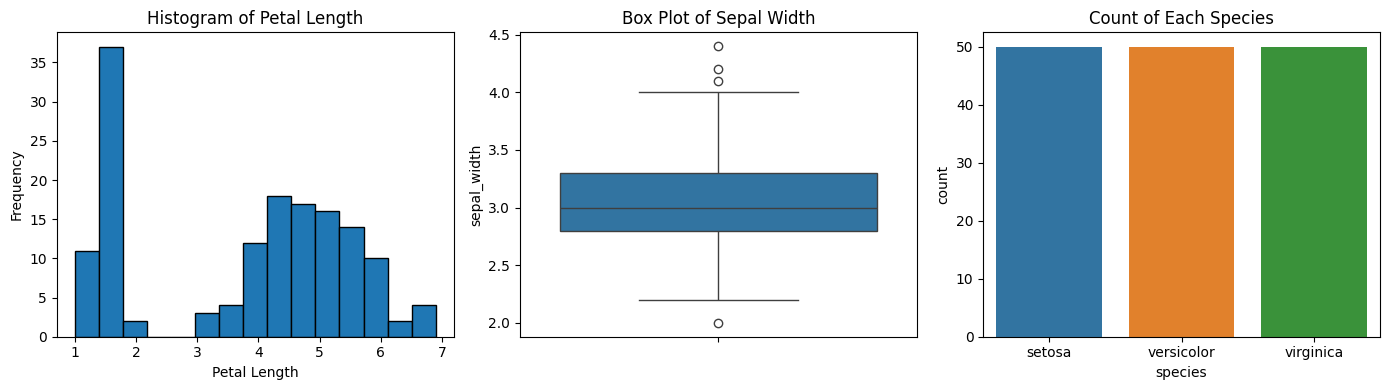

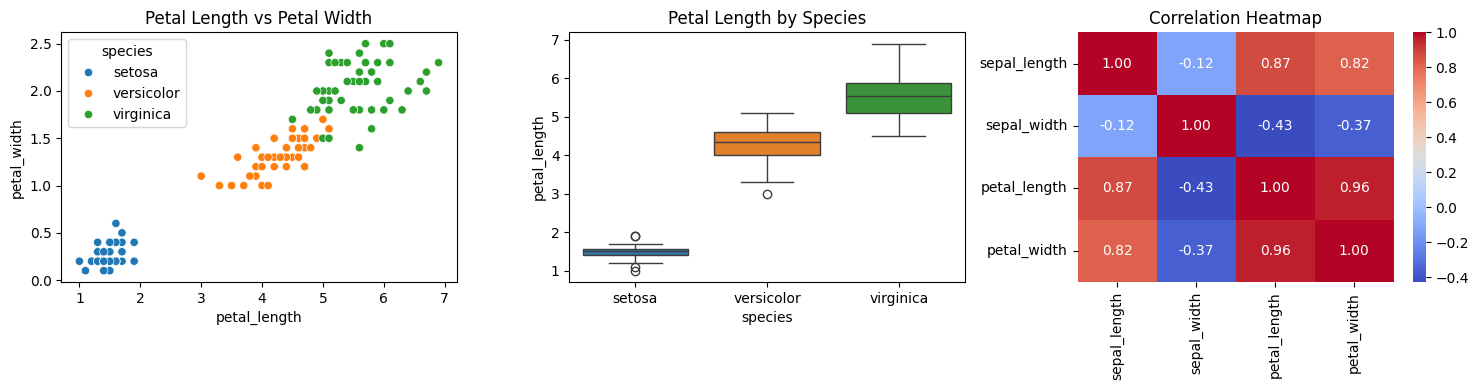

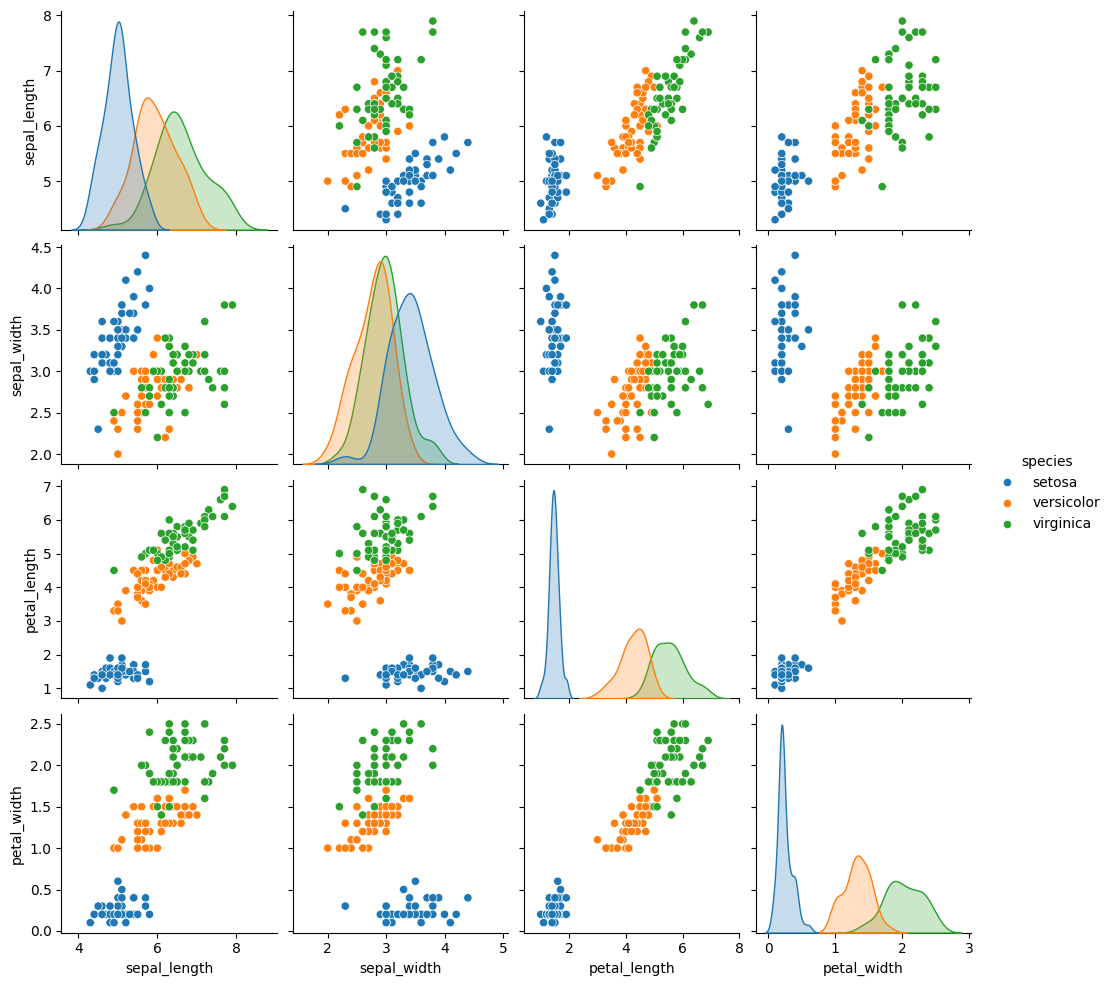


Summary statistics saved.


In [ ]:
##### PRACTICAL 1B #####
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_iris

# STEP 1: Load the Iris dataset
iris = load_iris(as_frame=True)
df = iris.frame

df["species"] = df["target"].map(
    dict(enumerate(iris.target_names))
)
df = df.drop(columns="target")
df.columns = [
    "sepal_length", "sepal_width",
    "petal_length", "petal_width", "species"
]

# STEP 2: Display the data
print("First five rows:\n", df.head())
print("\nShape:", df.shape)
print("\nDataset information:")
df.info()

# STEP 3: Summary statistics
print("\nDescriptive statistics:\n", df.describe().round(2))
print("\nMedian:\n", df.select_dtypes("number").median())
print("\nSkewness:\n", df.select_dtypes("number").skew().round(2))
print("\nSpecies count:\n", df["species"].value_counts())

# STEP 4: Univariate graphs
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

axes[0].hist(df["petal_length"], bins=15, edgecolor="black")
axes[0].set_title("Histogram of Petal Length")
axes[0].set_xlabel("Petal Length")
axes[0].set_ylabel("Frequency")

sns.boxplot(y=df["sepal_width"], ax=axes[1])
axes[1].set_title("Box Plot of Sepal Width")

sns.countplot(data=df, x="species", hue="species", ax=axes[2], legend=False)
axes[2].set_title("Count of Each Species")

plt.tight_layout()
plt.show()

# STEP 5: Bivariate graphs and correlation
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.scatterplot(
    data=df, x="petal_length", y="petal_width",
    hue="species", ax=axes[0]
)
axes[0].set_title("Petal Length vs Petal Width")

sns.boxplot(
    data=df, x="species", y="petal_length",
    hue="species", ax=axes[1], legend=False
)
axes[1].set_title("Petal Length by Species")

corr = df.drop(columns="species").corr()
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f", ax=axes[2])
axes[2].set_title("Correlation Heatmap")

plt.tight_layout()
plt.show()

# STEP 6: Pair plot
sns.pairplot(df, hue="species")
plt.show()

# Save the summary statistics
df.describe().to_csv("p1b_summary_statistics.csv")
print("\nSummary statistics saved.")


In [ ]:
#######PRACTICAL 1C
import pandas as pd
import numpy as np

from sklearn.preprocessing import (
    LabelEncoder, OrdinalEncoder, OneHotEncoder,
    MinMaxScaler, StandardScaler, MaxAbsScaler,
    Normalizer, Binarizer
)

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 20)

# STEP 1: Create sample data
data = {
    "name": ["Asha", "Bilal", "Chetan", "Divya", "Esha", "Farhan"],
    "city": ["Mumbai", "Pune", "Mumbai", "Delhi", "Pune", "Delhi"],
    "grade": ["Low", "High", "Medium", "High", "Low", "Medium"],
    "age": [21, 25, 23, 30, 22, 27],
    "income": [20000, 85000, 42000, 120000, 25000, 60000],
    "marks": [35, 88, 62, 95, 41, 70]
}

df = pd.DataFrame(data)
print("ORIGINAL DATA\n", df)

# STEP 2: Label encoding
le = LabelEncoder()
df["city_label"] = le.fit_transform(df["city"])
print("\nLabel encoding of city:")
print(dict(zip(le.classes_, le.transform(le.classes_))))

# STEP 3: Ordinal encoding
oe = OrdinalEncoder(categories=[["Low", "Medium", "High"]])
df["grade_ord"] = oe.fit_transform(df[["grade"]]).astype(int)
print("\nOrdinal encoding: Low=0, Medium=1, High=2")
print(df[["grade", "grade_ord"]])

# STEP 4: One-hot encoding
ohe = OneHotEncoder(sparse_output=False, handle_unknown="ignore")
onehot = ohe.fit_transform(df[["city"]])
onehot_df = pd.DataFrame(
    onehot,
    columns=ohe.get_feature_names_out(["city"])
)

print("\nONE-HOT ENCODING")
print(pd.concat([df[["city"]], onehot_df], axis=1))

# STEP 5: Feature scaling
num = df[["age", "income", "marks"]]

mm = MinMaxScaler()
std = StandardScaler()
mx = MaxAbsScaler()

minmax_df = pd.DataFrame(
    mm.fit_transform(num),
    columns=["age_mm", "income_mm", "marks_mm"]
)

standard_df = pd.DataFrame(
    std.fit_transform(num),
    columns=["age_z", "income_z", "marks_z"]
)

maxabs_df = pd.DataFrame(
    mx.fit_transform(num),
    columns=["age_ma", "income_ma", "marks_ma"]
)

print("\nMIN-MAX SCALED")
print(minmax_df.round(3))

print("\nSTANDARDIZED")
print(standard_df.round(3))

print("\nMAX-ABS SCALED")
print(maxabs_df.round(3))

# STEP 6: Normalization
norm = Normalizer(norm="l2")
rows_norm = norm.fit_transform(num)

print("\nROW NORMALIZATION")
print(np.round(rows_norm, 4))
print("Length of first row:", round(float(np.linalg.norm(rows_norm[0])), 4))

# STEP 7: Binarization
binz = Binarizer(threshold=50)
df["marks_pass"] = binz.fit_transform(df[["marks"]]).astype(int)

print("\nBINARIZATION OF MARKS")
print(df[["name", "marks", "marks_pass"]])

# STEP 8: Final model-ready table
final = pd.concat(
    [
        df[["name", "grade_ord", "marks_pass"]],
        onehot_df,
        minmax_df[["age_mm", "income_mm"]]
    ],
    axis=1
)

print("\nFINAL MODEL-READY TABLE")
print(final.round(3))

final.to_csv("p1c_preprocessed_data.csv", index=False)
print("\nSaved as p1c_preprocessed_data.csv")


ORIGINAL DATA
      name    city   grade  age  income  marks
0    Asha  Mumbai     Low   21   20000     35
1   Bilal    Pune    High   25   85000     88
2  Chetan  Mumbai  Medium   23   42000     62
3   Divya   Delhi    High   30  120000     95
4    Esha    Pune     Low   22   25000     41
5  Farhan   Delhi  Medium   27   60000     70

Label encoding of city:
{'Delhi': np.int64(0), 'Mumbai': np.int64(1), 'Pune': np.int64(2)}

Ordinal encoding: Low=0, Medium=1, High=2
    grade  grade_ord
0     Low          0
1    High          2
2  Medium          1
3    High          2
4     Low          0
5  Medium          1

ONE-HOT ENCODING
     city  city_Delhi  city_Mumbai  city_Pune
0  Mumbai         0.0          1.0        0.0
1    Pune         0.0          0.0        1.0
2  Mumbai         0.0          1.0        0.0
3   Delhi         1.0          0.0        0.0
4    Pune         0.0          0.0        1.0
5   Delhi         1.0          0.0        0.0

MIN-MAX SCALED
   age_mm  income_mm  mar

In [ ]:
######PRACTICAL 2A
import csv

# STEP 1: Create the training dataset
training_text = """Sky,AirTemp,Humidity,Wind,Water,Forecast,EnjoySport
Sunny,Warm,Normal,Strong,Warm,Same,Yes
Sunny,Warm,High,Strong,Warm,Same,Yes
Rainy,Cold,High,Strong,Warm,Change,No
Sunny,Warm,High,Strong,Cool,Change,Yes
"""

with open("enjoysport.csv", "w") as f:
    f.write(training_text)

# STEP 2: Read the CSV file
data = []

with open("enjoysport.csv", newline="") as f:
    reader = csv.reader(f)
    header = next(reader)

    for row in reader:
        data.append(row)

n_attr = len(header) - 1

print("Attributes:", header[:-1])
print("Total training examples:", len(data), "\n")

# STEP 3: Initialise the most specific hypothesis
hypothesis = ["0"] * n_attr
print("Initial hypothesis h0:", hypothesis)

# STEP 4: Apply the FIND-S algorithm
step = 0

for row in data:
    step += 1
    attributes, label = row[:-1], row[-1]

    if label == "Yes":
        for i in range(n_attr):
            if hypothesis[i] == "0":
                hypothesis[i] = attributes[i]
            elif hypothesis[i] != attributes[i]:
                hypothesis[i] = "?"

        print(
            "Example %d (%s): positive -> h%d = %s"
            % (step, ",".join(attributes), step, hypothesis)
        )
    else:
        print(
            "Example %d (%s): NEGATIVE -> ignored, h%d = %s"
            % (step, ",".join(attributes), step, hypothesis)
        )

# STEP 5: Display the final hypothesis
print("\nFINAL MOST SPECIFIC HYPOTHESIS:", hypothesis)

print(
    "Meaning: Sky=%s, AirTemp=%s, Humidity=%s, Wind=%s, Water=%s, Forecast=%s"
    % tuple(hypothesis)
)

# STEP 6: Test the hypothesis on a new day
def matches(h, x):
    return all(hv == "?" or hv == xv for hv, xv in zip(h, x))

new_day = ["Sunny", "Warm", "Low", "Strong", "Cool", "Same"]

prediction = "ENJOY (Yes)" if matches(hypothesis, new_day) else "NO enjoy"
print("\nNew day:", new_day, "->", prediction)


Attributes: ['Sky', 'AirTemp', 'Humidity', 'Wind', 'Water', 'Forecast']
Total training examples: 4 

Initial hypothesis h0: ['0', '0', '0', '0', '0', '0']
Example 1 (Sunny,Warm,Normal,Strong,Warm,Same): positive -> h1 = ['Sunny', 'Warm', 'Normal', 'Strong', 'Warm', 'Same']
Example 2 (Sunny,Warm,High,Strong,Warm,Same): positive -> h2 = ['Sunny', 'Warm', '?', 'Strong', 'Warm', 'Same']
Example 3 (Rainy,Cold,High,Strong,Warm,Change): NEGATIVE -> ignored, h3 = ['Sunny', 'Warm', '?', 'Strong', 'Warm', 'Same']
Example 4 (Sunny,Warm,High,Strong,Cool,Change): positive -> h4 = ['Sunny', 'Warm', '?', 'Strong', '?', '?']

FINAL MOST SPECIFIC HYPOTHESIS: ['Sunny', 'Warm', '?', 'Strong', '?', '?']
Meaning: Sky=Sunny, AirTemp=Warm, Humidity=?, Wind=Strong, Water=?, Forecast=?

New day: ['Sunny', 'Warm', 'Low', 'Strong', 'Cool', 'Same'] -> ENJOY (Yes)


First five students:
    hours  marks
0   4.00   53.1
1   8.61   83.8
2   6.86   74.3
3   5.79   74.0
4   2.25   49.9

Training rows: 45
Testing rows: 15

Intercept (b0): 35.566
Slope (b1): 5.824
Equation: marks = 35.57 + 5.82 * hours
Meaning: each extra hour of study adds about 5.8 marks.

Predicted marks for 7.5 hours: 79.2

MSE: 10.297
RMSE: 3.209 marks
MAE: 2.483 marks
R2: 0.935 (93.5% of variation explained)


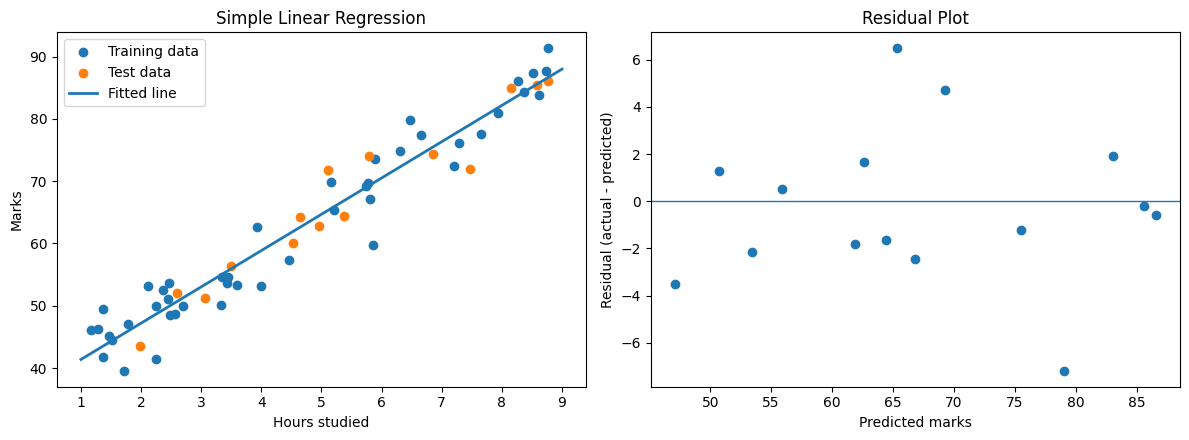


Data saved as p3a_student_marks.csv


In [ ]:
##############PRACTCIAL 3A
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    mean_squared_error,
    r2_score,
    mean_absolute_error
)

# STEP 1: Generate study-hours and marks data
rng = np.random.RandomState(42)

hours = rng.uniform(1, 9, 60)
marks = 35 + 6 * hours + rng.normal(0, 4, 60)

df = pd.DataFrame({
    "hours": hours.round(2),
    "marks": marks.round(1)
})

print("First five students:\n", df.head())

# STEP 2: Separate input X and target y
X = df[["hours"]]
y = df["marks"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=1
)

print("\nTraining rows:", len(X_train))
print("Testing rows:", len(X_test))

# STEP 3: Train the model
model = LinearRegression()
model.fit(X_train, y_train)

# STEP 4: Interpret the coefficients
print("\nIntercept (b0): %.3f" % model.intercept_)
print("Slope (b1): %.3f" % model.coef_[0])

print(
    "Equation: marks = %.2f + %.2f * hours"
    % (model.intercept_, model.coef_[0])
)

print(
    "Meaning: each extra hour of study adds about %.1f marks."
    % model.coef_[0]
)

# STEP 5: Make predictions
y_pred = model.predict(X_test)

new_student = pd.DataFrame({"hours": [7.5]})
new_prediction = model.predict(new_student)[0]

print("\nPredicted marks for 7.5 hours: %.1f" % new_prediction)

# STEP 6: Evaluate the model
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("\nMSE: %.3f" % mse)
print("RMSE: %.3f marks" % rmse)
print("MAE: %.3f marks" % mae)
print("R2: %.3f (%.1f%% of variation explained)" % (r2, r2 * 100))

# STEP 7: Plot the fitted line and residuals
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))

ax[0].scatter(X_train["hours"], y_train, label="Training data")
ax[0].scatter(X_test["hours"], y_test, label="Test data")

line_x = np.linspace(1, 9, 100)
line_df = pd.DataFrame({"hours": line_x})

ax[0].plot(
    line_x, model.predict(line_df),
    linewidth=2, label="Fitted line"
)

ax[0].set_xlabel("Hours studied")
ax[0].set_ylabel("Marks")
ax[0].set_title("Simple Linear Regression")
ax[0].legend()

residuals = y_test - y_pred
ax[1].scatter(y_pred, residuals)
ax[1].axhline(0, linewidth=1)
ax[1].set_xlabel("Predicted marks")
ax[1].set_ylabel("Residual (actual - predicted)")
ax[1].set_title("Residual Plot")

plt.tight_layout()
plt.show()

# Save the generated data
df.to_csv("p3a_student_marks.csv", index=False)
print("\nData saved as p3a_student_marks.csv")


Features: ['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']
Rows: 442 Columns: 10 



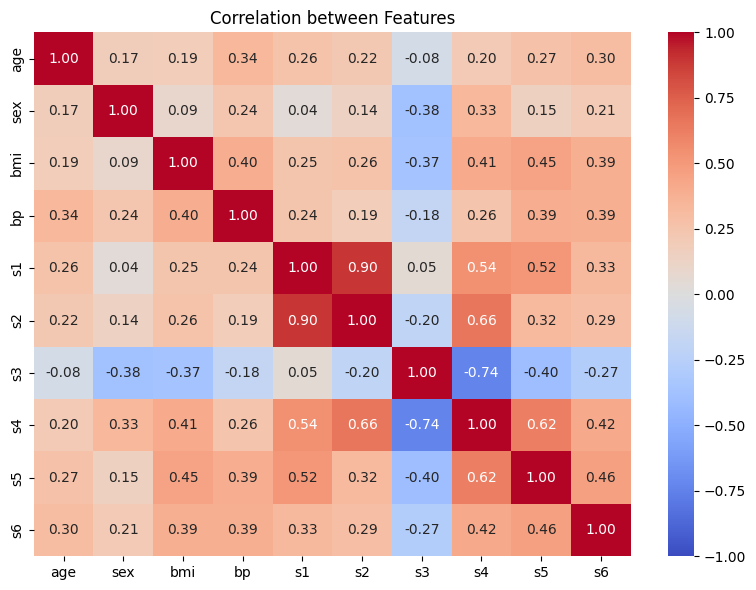

VIF of all features:
 s1     59.20
s2     39.19
s3     15.40
s5     10.08
s4      8.89
bmi     1.51
s6      1.48
bp      1.46
sex     1.28
age     1.22
dtype: float64 

ALL 10 features -> R2 = 0.359, MSE = 3180.2
Coefficients:
 age    -43.3
sex   -208.7
bmi    593.4
bp     302.9
s1    -560.2
s2     261.4
s3      -8.9
s4     135.9
s5     703.2
s6      28.3
dtype: float64 

SelectKBest chose: ['bmi', 'bp', 's3', 's4', 's5']
RFE chose: ['bmi', 'bp', 's1', 's2', 's5'] 

Dropping s1 (VIF = 53.63 )
Dropping s4 (VIF = 7.96 )
VIF method kept: ['age', 'sex', 'bmi', 'bp', 's2', 's3', 's5', 's6'] 

SelectKBest (5)    -> R2 = 0.322, MSE = 3364.6, max VIF = 3.19
RFE (5)            -> R2 = 0.329, MSE = 3332.8, max VIF = 7.62
VIF method (8)     -> R2 = 0.349, MSE = 3233.1, max VIF = 1.68

Final equation:
progression = 153.0 + -40.1*age + -202.6*sex + 601.1*bmi + 293.7*bp + -149.2*s2 + -290.7*s3 + 510.4*s5 + 31.0*s6


In [ ]:
###########PRACTICAL 3B
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_diabetes
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.feature_selection import RFE, SelectKBest, f_regression

# STEP 1: Load the Diabetes dataset
d = load_diabetes(as_frame=True)
X = d.data
y = d.target

print("Features:", list(X.columns))
print("Rows:", X.shape[0], "Columns:", X.shape[1], "\n")

# STEP 2: Display the correlation matrix
corr = X.corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm",
            vmin=-1, vmax=1)
plt.title("Correlation between Features")
plt.tight_layout()
plt.show()

# STEP 3: Calculate Variance Inflation Factor (VIF)
def compute_vif(frame):
    vifs = {}

    for col in frame.columns:
        others = frame.drop(columns=col)
        r2 = LinearRegression().fit(others, frame[col]).score(
            others, frame[col]
        )
        vifs[col] = 1.0 / (1.0 - r2)

    return pd.Series(vifs).round(2).sort_values(ascending=False)

print("VIF of all features:\n", compute_vif(X), "\n")

# STEP 4: Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=0
)

# Train using all features
full = LinearRegression().fit(X_train, y_train)
pred_full = full.predict(X_test)

print(
    "ALL 10 features -> R2 = %.3f, MSE = %.1f"
    % (
        r2_score(y_test, pred_full),
        mean_squared_error(y_test, pred_full)
    )
)

print("Coefficients:\n",
      pd.Series(full.coef_, index=X.columns).round(1), "\n")

# STEP 5: Feature selection using SelectKBest
skb = SelectKBest(score_func=f_regression, k=5)
skb.fit(X_train, y_train)

kbest = list(X.columns[skb.get_support()])
print("SelectKBest chose:", kbest)

# STEP 6: Feature selection using RFE
rfe = RFE(
    LinearRegression(),
    n_features_to_select=5
)
rfe.fit(X_train, y_train)

rfe_feats = list(X.columns[rfe.support_])
print("RFE chose:", rfe_feats, "\n")

# STEP 7: Remove features with high VIF
vif_feats = list(X.columns)

while len(vif_feats) > 2 and compute_vif(
    X_train[vif_feats]
).max() > 5:
    current_vif = compute_vif(X_train[vif_feats])
    worst = current_vif.idxmax()

    print("Dropping", worst, "(VIF =", current_vif.max(), ")")
    vif_feats.remove(worst)

print("VIF method kept:", vif_feats, "\n")

# STEP 8: Compare the selected feature sets
for name, feats in [
    ("SelectKBest (5)", kbest),
    ("RFE (5)", rfe_feats),
    ("VIF method (%d)" % len(vif_feats), vif_feats)
]:
    model = LinearRegression().fit(X_train[feats], y_train)
    pred = model.predict(X_test[feats])

    max_vif = compute_vif(X_train[feats]).max()

    print(
        "%-18s -> R2 = %.3f, MSE = %.1f, max VIF = %.2f"
        % (
            name,
            r2_score(y_test, pred),
            mean_squared_error(y_test, pred),
            max_vif
        )
    )

# STEP 9: Print the final equation using VIF-selected features
final = LinearRegression().fit(X_train[vif_feats], y_train)

terms = " + ".join(
    "%.1f*%s" % (coef, feature)
    for coef, feature in zip(final.coef_, vif_feats)
)

print("\nFinal equation:")
print("progression = %.1f + %s" % (final.intercept_, terms))


True non-zero coefficients at positions: [ 2 13 19 22 30] 

                       Model  Train R2  Test R2  Test MSE  Non-zero coefs
         Linear (no penalty)     0.939    0.385  4753.673              40
            Ridge (alpha=30)     0.826    0.620  2942.433              40
             Lasso (alpha=3)     0.906    0.810  1472.135              15
ElasticNet (alpha=3, l1=0.5)     0.636    0.474  4071.233              34 

Best Ridge alpha: 11.721 -> test R2 = 0.658
Best Lasso alpha: 4.344 -> test R2 = 0.815
Features kept by tuned Lasso: [ 2  4  8 13 17 19 27 28 30 31 35] 



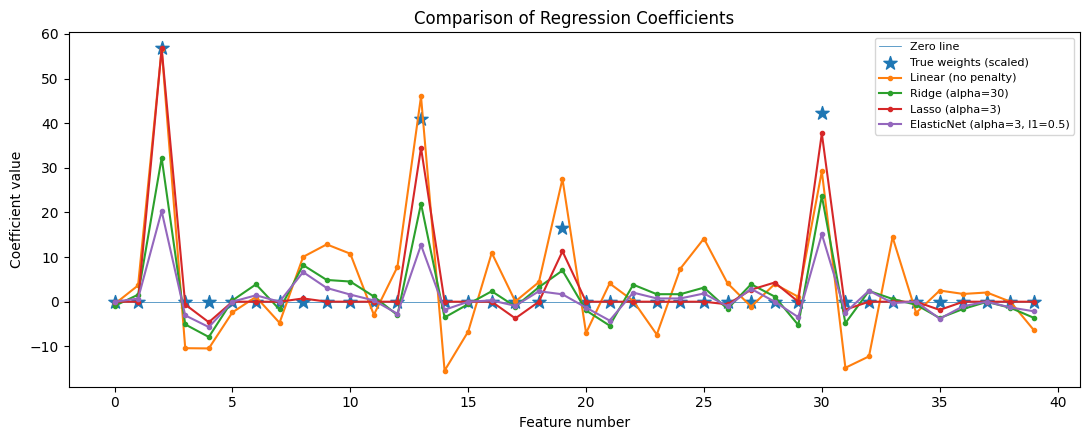

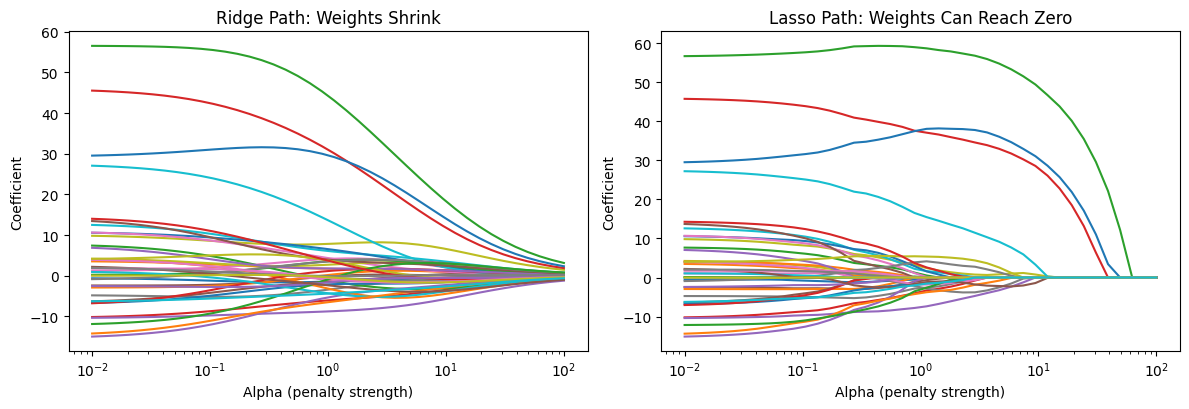


Results saved as p3c_model_comparison.csv


In [ ]:
##########PRACTICAL 3C
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_regression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import (
    LinearRegression, Ridge, Lasso, ElasticNet, RidgeCV, LassoCV
)
from sklearn.metrics import mean_squared_error, r2_score

# STEP 1: Generate data
X, y, true_coef = make_regression(
    n_samples=80,
    n_features=40,
    n_informative=5,
    noise=30,
    coef=True,
    random_state=3
)

print("True non-zero coefficients at positions:",
      np.nonzero(true_coef)[0], "\n")

# STEP 2: Split the data and scale the features
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=0
)

scaler = StandardScaler().fit(X_train)
X_train_s = scaler.transform(X_train)
X_test_s = scaler.transform(X_test)

# STEP 3: Train four models
models = {
    "Linear (no penalty)": LinearRegression(),
    "Ridge (alpha=30)": Ridge(alpha=30),
    "Lasso (alpha=3)": Lasso(alpha=3, max_iter=10000),
    "ElasticNet (alpha=3, l1=0.5)": ElasticNet(
        alpha=3, l1_ratio=0.5, max_iter=10000
    )
}

rows = []
coefs = {}

for name, model in models.items():
    model.fit(X_train_s, y_train)
    pred = model.predict(X_test_s)

    coefs[name] = model.coef_

    rows.append([
        name,
        r2_score(y_train, model.predict(X_train_s)),
        r2_score(y_test, pred),
        mean_squared_error(y_test, pred),
        int(np.sum(np.abs(model.coef_) > 1e-6))
    ])

result = pd.DataFrame(
    rows,
    columns=[
        "Model", "Train R2", "Test R2",
        "Test MSE", "Non-zero coefs"
    ]
)

print(result.round(3).to_string(index=False), "\n")

# STEP 4: Tune alpha using cross-validation
ridge_cv = RidgeCV(
    alphas=np.logspace(-1, 3, 30)
).fit(X_train_s, y_train)

lasso_cv = LassoCV(
    alphas=np.logspace(-1, 1.5, 30),
    cv=5,
    max_iter=10000
).fit(X_train_s, y_train)

print(
    "Best Ridge alpha:", round(ridge_cv.alpha_, 3),
    "-> test R2 = %.3f" % ridge_cv.score(X_test_s, y_test)
)

print(
    "Best Lasso alpha:", round(lasso_cv.alpha_, 3),
    "-> test R2 = %.3f" % lasso_cv.score(X_test_s, y_test)
)

print("Features kept by tuned Lasso:",
      np.nonzero(lasso_cv.coef_)[0], "\n")

# STEP 5: Plot learned coefficients
fig, ax = plt.subplots(figsize=(11, 4.5))
idx = np.arange(40)

ax.plot(idx, np.zeros(40), linewidth=0.5, label="Zero line")

# True coefficients on the original data scale
true_scaled = true_coef * scaler.scale_
ax.scatter(
    idx, true_scaled, marker="*", s=100,
    label="True weights (scaled)"
)

for name, coef in coefs.items():
    ax.plot(idx, coef, marker="o", markersize=3, label=name)

ax.set_xlabel("Feature number")
ax.set_ylabel("Coefficient value")
ax.set_title("Comparison of Regression Coefficients")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

# STEP 6: Plot regularisation paths
alphas = np.logspace(-2, 2, 40)

lasso_path = [
    Lasso(alpha=a, max_iter=10000).fit(
        X_train_s, y_train
    ).coef_
    for a in alphas
]

ridge_path = [
    Ridge(alpha=a * 10).fit(
        X_train_s, y_train
    ).coef_
    for a in alphas
]

fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))

ax[0].plot(alphas, np.array(ridge_path))
ax[0].set_xscale("log")
ax[0].set_title("Ridge Path: Weights Shrink")
ax[0].set_xlabel("Alpha (penalty strength)")
ax[0].set_ylabel("Coefficient")

ax[1].plot(alphas, np.array(lasso_path))
ax[1].set_xscale("log")
ax[1].set_title("Lasso Path: Weights Can Reach Zero")
ax[1].set_xlabel("Alpha (penalty strength)")
ax[1].set_ylabel("Coefficient")

plt.tight_layout()
plt.show()

# STEP 7: Save model comparison results
result.to_csv("p3c_model_comparison.csv", index=False)
print("\nResults saved as p3c_model_comparison.csv")


Rows, columns: (569, 30)
Classes: {'malignant': 212, 'benign': 357} 

First 5 predicted probabilities: [0.969 0.    0.559 0.939 0.175]
First 5 predicted labels: [1 0 1 1 0]
First 5 actual labels: [1 0 1 1 0] 

Confusion matrix [[TN FP] [FN TP]]:
 [[52  1]
 [ 1 89]]

Accuracy : 0.9860
Precision: 0.9889
Recall   : 0.9889
F1-score : 0.9889
ROC-AUC  : 0.9977


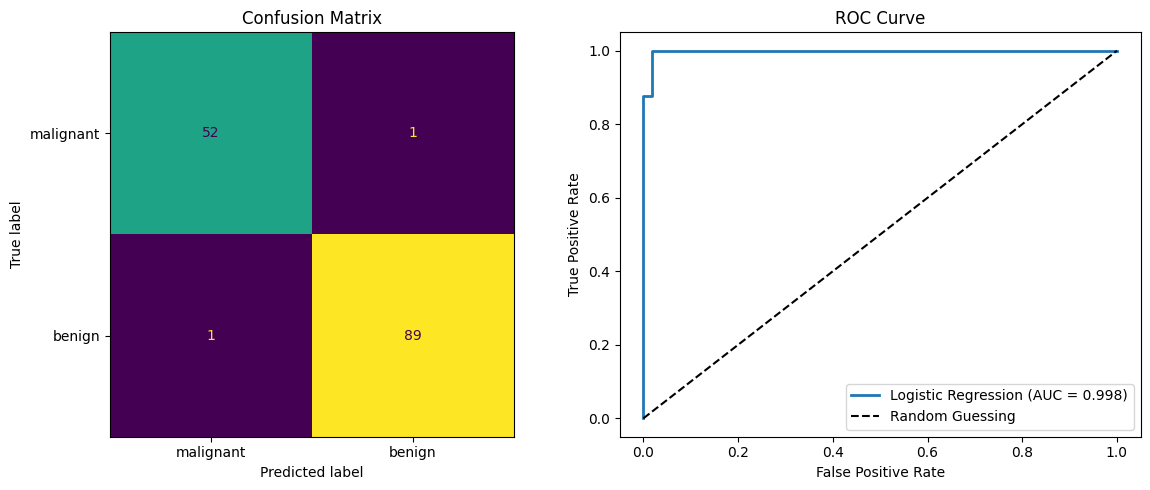

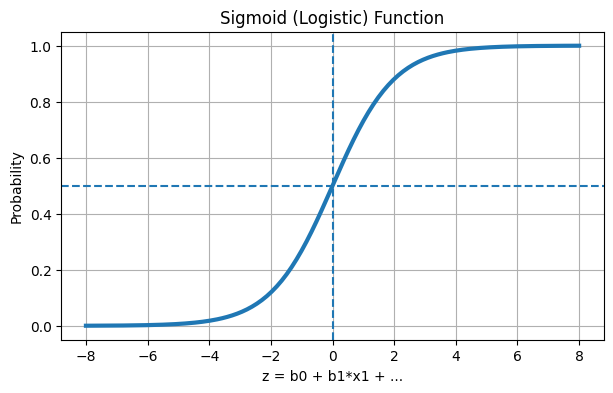

In [ ]:
# PRACTICAL 4(a): LOGISTIC REGRESSION
# Google Colab-ready code

import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    roc_curve,
    roc_auc_score,
    ConfusionMatrixDisplay
)

# STEP 1: Load the dataset
data = load_breast_cancer()
X, y = data.data, data.target

print("Rows, columns:", X.shape)
print(
    "Classes:",
    {
        str(name): int(count)
        for name, count in zip(
            data.target_names, np.bincount(y)
        )
    },
    "\n"
)

# STEP 2: Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    stratify=y,
    random_state=42
)

# Scale the features
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

# STEP 3: Train the Logistic Regression model
model = LogisticRegression(max_iter=1000)
model.fit(X_train_s, y_train)

# STEP 4: Make predictions
y_pred = model.predict(X_test_s)
y_prob = model.predict_proba(X_test_s)[:, 1]

print("First 5 predicted probabilities:", y_prob[:5].round(3))
print("First 5 predicted labels:", y_pred[:5])
print("First 5 actual labels:", y_test[:5], "\n")

# STEP 5: Evaluate the model
cm = confusion_matrix(y_test, y_pred)
print("Confusion matrix [[TN FP] [FN TP]]:\n", cm)

print("\nAccuracy : %.4f" % accuracy_score(y_test, y_pred))
print("Precision: %.4f" % precision_score(y_test, y_pred))
print("Recall   : %.4f" % recall_score(y_test, y_pred))
print("F1-score : %.4f" % f1_score(y_test, y_pred))
print("ROC-AUC  : %.4f" % roc_auc_score(y_test, y_prob))

# STEP 6: Display the confusion matrix and ROC curve
fpr, tpr, thresholds = roc_curve(y_test, y_prob)

fig, ax = plt.subplots(1, 2, figsize=(12, 5))

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=data.target_names
).plot(ax=ax[0], colorbar=False)

ax[0].set_title("Confusion Matrix")

ax[1].plot(
    fpr,
    tpr,
    lw=2,
    label="Logistic Regression (AUC = %.3f)"
    % roc_auc_score(y_test, y_prob)
)
ax[1].plot([0, 1], [0, 1], "k--", label="Random Guessing")
ax[1].set_xlabel("False Positive Rate")
ax[1].set_ylabel("True Positive Rate")
ax[1].set_title("ROC Curve")
ax[1].legend(loc="lower right")

plt.tight_layout()
plt.show()

# STEP 7: Plot the sigmoid function
z = np.linspace(-8, 8, 200)
sigmoid = 1 / (1 + np.exp(-z))

plt.figure(figsize=(7, 4))
plt.plot(z, sigmoid, linewidth=3)
plt.axhline(0.5, linestyle="--")
plt.axvline(0, linestyle="--")
plt.xlabel("z = b0 + b1*x1 + ...")
plt.ylabel("Probability")
plt.title("Sigmoid (Logistic) Function")
plt.grid(True)
plt.show()

In [ ]:
######### PRACTICAL 4B
# STEP 1: Import libraries
import pandas as pd
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix

# STEP 2: Create iris.csv
iris = load_iris(as_frame=True)
df = iris.frame.copy()

df["species"] = df["target"].map(
    dict(enumerate(iris.target_names))
)
df = df.drop(columns="target")
df.columns = [
    "sepal_length", "sepal_width",
    "petal_length", "petal_width", "species"
]
df.to_csv("iris.csv", index=False)

# STEP 3: Read the CSV file
df = pd.read_csv("iris.csv")
print("First five rows:\n", df.head(), "\n")

X = df.drop(columns="species")
y = df["species"]

# STEP 4: Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2,
    random_state=3, stratify=y
)

print("Training samples:", len(X_train))
print("Test samples:", len(X_test))

# STEP 5: Train the KNN model
knn = KNeighborsClassifier(
    n_neighbors=5, metric="euclidean"
)
knn.fit(X_train, y_train)

# STEP 6: Predict test samples
y_pred = knn.predict(X_test)
correct = 0
wrong = 0

print("\nNo. | Actual | Predicted | Result")

for i, (actual, pred) in enumerate(
    zip(y_test.values, y_pred), start=1
):
    is_correct = actual == pred
    correct += int(is_correct)
    wrong += int(not is_correct)

    print(
        f"{i:2d} | {actual:10s} | {pred:10s} | "
        f"{'CORRECT' if is_correct else 'WRONG'}"
    )

print("\nCorrect predictions:", correct)
print("Wrong predictions:", wrong)
print("Accuracy: %.2f%%" % (100 * accuracy_score(y_test, y_pred)))

# STEP 7: Predict one new flower
sample = pd.DataFrame(
    [[5.9, 3.0, 5.1, 1.8]],
    columns=X.columns
)

print("\nNew sample:", sample.values[0])
print("Predicted species:", knn.predict(sample)[0])

distances, indices = knn.kneighbors(sample)
print("\nFive nearest neighbours:")

for distance, index in zip(distances[0], indices[0]):
    print("Distance: %.3f -> %s" % (
        distance, y_train.iloc[index]
    ))

print("\nClass probabilities:")
print(dict(zip(knn.classes_, knn.predict_proba(sample)[0].round(2))))

# STEP 8: Try different values of k
print("\nk | Test accuracy")

for k in [1, 3, 5, 7, 9, 11, 15]:
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train, y_train)
    print(k, "|", round(model.score(X_test, y_test), 3))

# STEP 9: Confusion matrix
print("\nConfusion matrix:\n", confusion_matrix(y_test, y_pred))

First five rows:
    sepal_length  sepal_width  petal_length  petal_width species
0           5.1          3.5           1.4          0.2  setosa
1           4.9          3.0           1.4          0.2  setosa
2           4.7          3.2           1.3          0.2  setosa
3           4.6          3.1           1.5          0.2  setosa
4           5.0          3.6           1.4          0.2  setosa 

Training samples: 120
Test samples: 30

No. | Actual | Predicted | Result
 1 | virginica  | virginica  | CORRECT
 2 | versicolor | versicolor | CORRECT
 3 | versicolor | virginica  | WRONG
 4 | setosa     | setosa     | CORRECT
 5 | virginica  | virginica  | CORRECT
 6 | virginica  | virginica  | CORRECT
 7 | virginica  | virginica  | CORRECT
 8 | virginica  | virginica  | CORRECT
 9 | versicolor | versicolor | CORRECT
10 | versicolor | versicolor | CORRECT
11 | versicolor | virginica  | WRONG
12 | virginica  | virginica  | CORRECT
13 | versicolor | versicolor | CORRECT
14 | versicolor | v

Unrestricted tree -> depth = 6 | leaves = 16
Training accuracy: 1.0
Testing accuracy: 0.906
max_depth= 1 | train=0.920 | test=0.918
max_depth= 2 | train=0.957 | test=0.895
max_depth= 3 | train=0.975 | test=0.924
max_depth= 4 | train=0.987 | test=0.936
max_depth= 5 | train=0.997 | test=0.930
max_depth= 6 | train=1.000 | test=0.906
max_depth= 7 | train=1.000 | test=0.906
max_depth= 8 | train=1.000 | test=0.906
max_depth= 9 | train=1.000 | test=0.906
max_depth=10 | train=1.000 | test=0.906
max_depth=11 | train=1.000 | test=0.906
max_depth=12 | train=1.000 | test=0.906

Best depth on test data: 4

Pruned tree:
Leaves: 7
Training accuracy: 0.97
Testing accuracy: 0.93


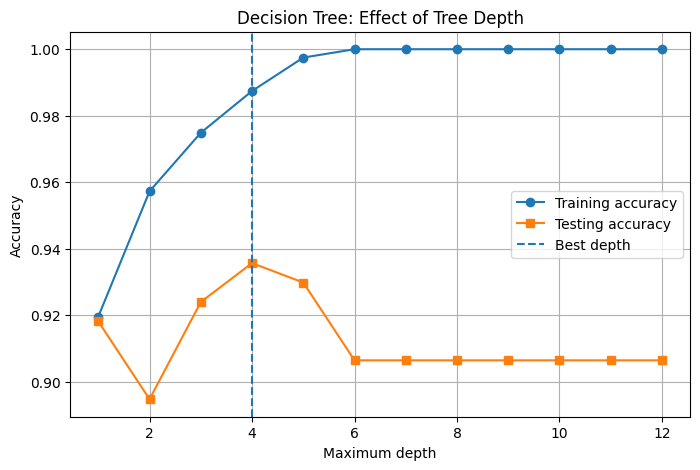

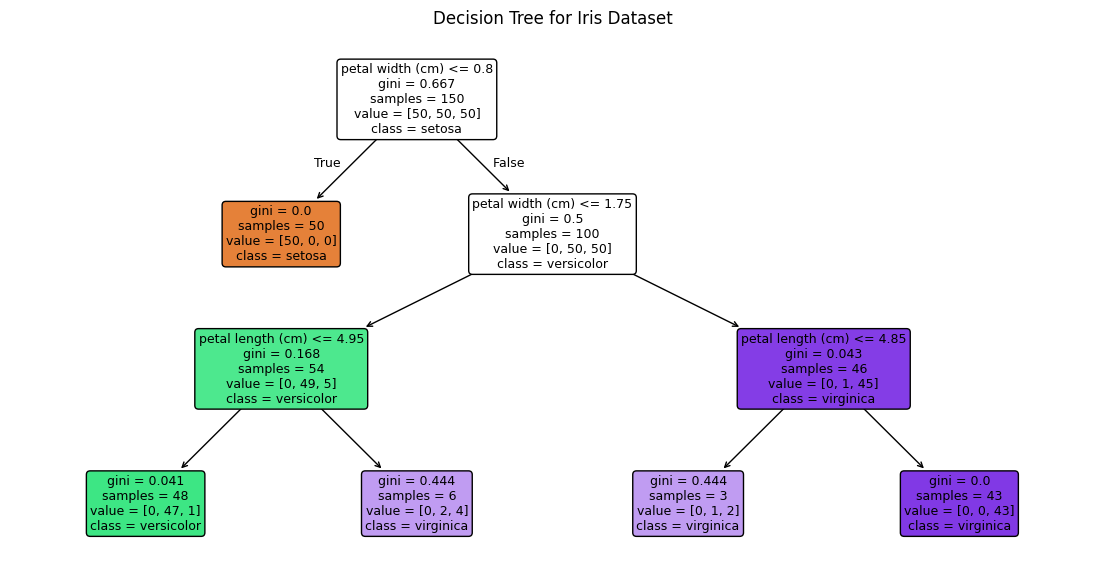


Tree as text rules:

|--- petal width (cm) <= 0.80
|   |--- class: 0
|--- petal width (cm) >  0.80
|   |--- petal width (cm) <= 1.75
|   |   |--- petal length (cm) <= 4.95
|   |   |   |--- class: 1
|   |   |--- petal length (cm) >  4.95
|   |   |   |--- class: 2
|   |--- petal width (cm) >  1.75
|   |   |--- petal length (cm) <= 4.85
|   |   |   |--- class: 2
|   |   |--- petal length (cm) >  4.85
|   |   |   |--- class: 2


Top five important features:
worst perimeter           0.797
worst texture             0.101
worst concave points      0.064
worst smoothness          0.024
worst radius              0.015


In [ ]:
# PRACTICAL 4(c): DECISION TREE

import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer, load_iris
from sklearn.model_selection import train_test_split
from sklearn.tree import (
    DecisionTreeClassifier, plot_tree, export_text
)

# STEP 1: Load breast cancer data and split it
data = load_breast_cancer()

X_train, X_test, y_train, y_test = train_test_split(
    data.data, data.target,
    test_size=0.3,
    random_state=3,
    stratify=data.target
)

# STEP 2: Train an unrestricted decision tree
deep = DecisionTreeClassifier(random_state=0)
deep.fit(X_train, y_train)

print("Unrestricted tree -> depth =", deep.get_depth(),
      "| leaves =", deep.get_n_leaves())
print("Training accuracy:", round(deep.score(X_train, y_train), 3))
print("Testing accuracy:", round(deep.score(X_test, y_test), 3))

# STEP 3: Try different maximum depths
depths = range(1, 13)
train_acc = []
test_acc = []

for d in depths:
    tree = DecisionTreeClassifier(
        max_depth=d, random_state=0
    )
    tree.fit(X_train, y_train)

    train_score = tree.score(X_train, y_train)
    test_score = tree.score(X_test, y_test)

    train_acc.append(train_score)
    test_acc.append(test_score)

    print(
        f"max_depth={d:2d} | "
        f"train={train_score:.3f} | test={test_score:.3f}"
    )

best_depth = list(depths)[int(np.argmax(test_acc))]
print("\nBest depth on test data:", best_depth)

# STEP 4: Create a pruned tree
pruned = DecisionTreeClassifier(
    max_depth=4,
    min_samples_leaf=5,
    min_samples_split=10,
    ccp_alpha=0.005,
    random_state=0
)
pruned.fit(X_train, y_train)

print("\nPruned tree:")
print("Leaves:", pruned.get_n_leaves())
print("Training accuracy:", round(pruned.score(X_train, y_train), 3))
print("Testing accuracy:", round(pruned.score(X_test, y_test), 3))

# STEP 5: Plot training and testing accuracy
plt.figure(figsize=(8, 5))
plt.plot(depths, train_acc, "o-", label="Training accuracy")
plt.plot(depths, test_acc, "s-", label="Testing accuracy")
plt.axvline(best_depth, linestyle="--", label="Best depth")
plt.xlabel("Maximum depth")
plt.ylabel("Accuracy")
plt.title("Decision Tree: Effect of Tree Depth")
plt.legend()
plt.grid(True)
plt.show()

# STEP 6: Visualise a small tree using Iris data
iris = load_iris()

small = DecisionTreeClassifier(
    max_depth=3, random_state=0
)
small.fit(iris.data, iris.target)

plt.figure(figsize=(14, 7))
plot_tree(
    small,
    feature_names=iris.feature_names,
    class_names=iris.target_names,
    filled=True,
    rounded=True,
    fontsize=9
)
plt.title("Decision Tree for Iris Dataset")
plt.show()

# STEP 7: Print the tree rules
print("\nTree as text rules:\n")
print(export_text(small, feature_names=iris.feature_names))

# STEP 8: Display the five most important features
important_features = sorted(
    zip(pruned.feature_importances_, data.feature_names),
    reverse=True
)[:5]

print("\nTop five important features:")
for score, name in important_features:
    print(f"{name:25s} {score:.3f}")

Kernel comparison on breast-cancer data
linear   test accuracy = 0.9650
poly     test accuracy = 0.9021
rbf      test accuracy = 0.9790
sigmoid  test accuracy = 0.9510

Classification report (RBF):
              precision    recall  f1-score   support

   malignant       1.00      0.94      0.97        53
      benign       0.97      1.00      0.98        90

    accuracy                           0.98       143
   macro avg       0.98      0.97      0.98       143
weighted avg       0.98      0.98      0.98       143

Support vectors per class: [54 48]

Effect of C (gamma='scale')
C = 0.01    train accuracy = 0.627 test accuracy = 0.629
C = 0.1     train accuracy = 0.948 test accuracy = 0.944
C = 1       train accuracy = 0.988 test accuracy = 0.979
C = 10      train accuracy = 0.995 test accuracy = 0.965
C = 100     train accuracy = 1.000 test accuracy = 0.965
C = 1000    train accuracy = 1.000 test accuracy = 0.965


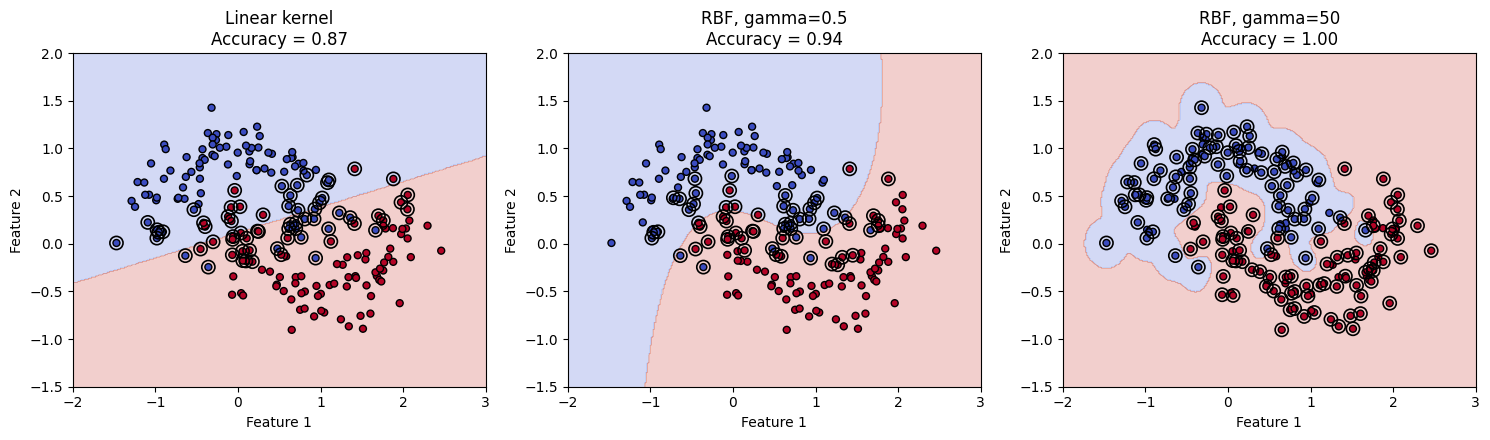

In [ ]:

# Practical 4(d): Support Vector Machine (SVM)

import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer, make_moons
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.svm import SVC
from sklearn.metrics import classification_report

# STEP 1: Load breast cancer dataset and split it
data = load_breast_cancer()

X_train, X_test, y_train, y_test = train_test_split(
    data.data,
    data.target,
    test_size=0.25,
    random_state=1,
    stratify=data.target
)

# STEP 2: Compare different kernels
print("Kernel comparison on breast-cancer data")

for kernel in ["linear", "poly", "rbf", "sigmoid"]:
    clf = make_pipeline(
        StandardScaler(),
        SVC(kernel=kernel)
    )
    clf.fit(X_train, y_train)

    print(f"{kernel:8s} test accuracy = {clf.score(X_test, y_test):.4f}")

# STEP 3: Classification report using RBF kernel
best = make_pipeline(
    StandardScaler(),
    SVC(kernel="rbf", C=1.0, gamma="scale")
)

best.fit(X_train, y_train)

print("\nClassification report (RBF):")
print(classification_report(
    y_test,
    best.predict(X_test),
    target_names=data.target_names
))

svc = best.named_steps["svc"]
print("Support vectors per class:", svc.n_support_)

# STEP 4: Study the effect of C
print("\nEffect of C (gamma='scale')")

for C in [0.01, 0.1, 1, 10, 100, 1000]:
    model = make_pipeline(
        StandardScaler(),
        SVC(C=C)
    )
    model.fit(X_train, y_train)

    print(
        f"C = {C:<7g} "
        f"train accuracy = {model.score(X_train, y_train):.3f} "
        f"test accuracy = {model.score(X_test, y_test):.3f}"
    )

# STEP 5: Create curved data
Xm, ym = make_moons(
    n_samples=200,
    noise=0.25,
    random_state=4
)

configs = [
    ("Linear kernel", SVC(kernel="linear", C=1)),
    ("RBF, gamma=0.5", SVC(kernel="rbf", gamma=0.5, C=1)),
    ("RBF, gamma=50", SVC(kernel="rbf", gamma=50, C=100))
]

xx, yy = np.meshgrid(
    np.linspace(-2, 3, 300),
    np.linspace(-1.5, 2, 300)
)

# STEP 6: Plot decision boundaries
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

for ax, (title, model) in zip(axes, configs):
    model.fit(Xm, ym)

    zz = model.predict(
        np.c_[xx.ravel(), yy.ravel()]
    ).reshape(xx.shape)

    ax.contourf(xx, yy, zz, alpha=0.25, cmap="coolwarm")

    ax.scatter(
        Xm[:, 0], Xm[:, 1],
        c=ym, cmap="coolwarm",
        edgecolor="k", s=25
    )

    # Circle the support vectors
    ax.scatter(
        model.support_vectors_[:, 0],
        model.support_vectors_[:, 1],
        s=90, facecolors="none",
        edgecolors="black", linewidths=1.2
    )

    ax.set_title(
        f"{title}\nAccuracy = {model.score(Xm, ym):.2f}"
    )
    ax.set_xlabel("Feature 1")
    ax.set_ylabel("Feature 2")

plt.tight_layout()
plt.show()


Single decision tree: mean CV accuracy = 0.9174 (+/- 0.0164)
Random forest (100): mean CV accuracy = 0.9631 (+/- 0.0217)
Forest is better by 4.57 percentage points

Number of trees -> test accuracy
   1 trees -> 0.9298
   2 trees -> 0.9298
   5 trees -> 0.9766
  10 trees -> 0.9766
  25 trees -> 0.9708
  50 trees -> 0.9766
 100 trees -> 0.9825
 200 trees -> 0.9766
 400 trees -> 0.9825

max_features -> test accuracy
1     -> 0.9649
3     -> 0.9708
sqrt  -> 0.9766
15    -> 0.9766
all   -> 0.9766

OOB score = 0.9648, test score = 0.9825

Top-10 features:
worst area                 0.1279
worst radius               0.1238
worst perimeter            0.1149
worst concave points       0.0897
mean concave points        0.0813
mean perimeter             0.0749
mean area                  0.0560
mean concavity             0.0476
mean radius                0.0375
area error                 0.0312


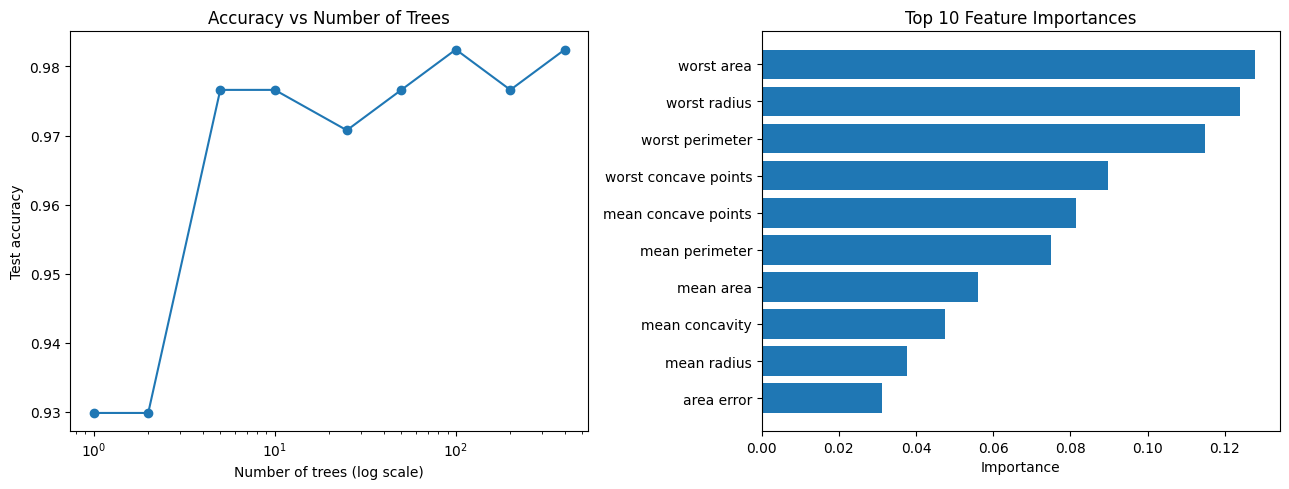

In [ ]:

# Practical 4(e): Random Forest Ensemble

import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# STEP 1: Load and split the dataset
data = load_breast_cancer()
X, y = data.data, data.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.3,
    random_state=5,
    stratify=y
)

# STEP 2: Compare Decision Tree and Random Forest
tree = DecisionTreeClassifier(random_state=0)

forest = RandomForestClassifier(
    n_estimators=100,
    random_state=0
)

cv_tree = cross_val_score(tree, X, y, cv=5)
cv_forest = cross_val_score(forest, X, y, cv=5)

print("Single decision tree: mean CV accuracy = "
      f"{cv_tree.mean():.4f} (+/- {cv_tree.std():.4f})")

print("Random forest (100): mean CV accuracy = "
      f"{cv_forest.mean():.4f} (+/- {cv_forest.std():.4f})")

print("Forest is better by "
      f"{100 * (cv_forest.mean() - cv_tree.mean()):.2f} "
      "percentage points\n")

# STEP 3: Experiment with the number of trees
counts = [1, 2, 5, 10, 25, 50, 100, 200, 400]
scores = []

print("Number of trees -> test accuracy")

for n in counts:
    rf = RandomForestClassifier(
        n_estimators=n,
        random_state=0
    )
    rf.fit(X_train, y_train)

    accuracy = rf.score(X_test, y_test)
    scores.append(accuracy)

    print(f"{n:4d} trees -> {accuracy:.4f}")

# STEP 4: Experiment with max_features
print("\nmax_features -> test accuracy")

mf_names = [1, 3, "sqrt", 15, "all"]
mf_scores = []

for mf in mf_names:
    value = None if mf == "all" else mf

    rf = RandomForestClassifier(
        n_estimators=200,
        max_features=value,
        random_state=0
    )
    rf.fit(X_train, y_train)

    accuracy = rf.score(X_test, y_test)
    mf_scores.append(accuracy)

    print(f"{str(mf):5s} -> {accuracy:.4f}")

# STEP 5: Out-of-bag (OOB) score
rf = RandomForestClassifier(
    n_estimators=300,
    oob_score=True,
    random_state=0
)
rf.fit(X_train, y_train)

print(f"\nOOB score = {rf.oob_score_:.4f}, "
      f"test score = {rf.score(X_test, y_test):.4f}")

# STEP 6: Display the top 10 important features
order = np.argsort(rf.feature_importances_)[::-1][:10]

print("\nTop-10 features:")
for i in order:
    print(f"{data.feature_names[i]:26s} "
          f"{rf.feature_importances_[i]:.4f}")

# STEP 7: Plot tree count and feature importance
fig, ax = plt.subplots(1, 2, figsize=(13, 5))

ax[0].plot(counts, scores, "o-")
ax[0].set_xscale("log")
ax[0].set_xlabel("Number of trees (log scale)")
ax[0].set_ylabel("Test accuracy")
ax[0].set_title("Accuracy vs Number of Trees")

ax[1].barh(
    [data.feature_names[i] for i in order][::-1],
    rf.feature_importances_[order][::-1]
)
ax[1].set_xlabel("Importance")
ax[1].set_title("Top 10 Feature Importances")

plt.tight_layout()
plt.show()


In [ ]:

######INSTALL THIS PACHKAGE FOR 4F PRAC
!pip -q install xgboost


Training samples: 341
Validation samples: 114
Test samples: 114

Baseline -> validation accuracy = 0.9912, test accuracy = 0.9649

Best parameters: {'learning_rate': 0.3, 'max_depth': 2, 'n_estimators': 150, 'subsample': 1.0}
Best CV accuracy: 0.9539

Tuned model test accuracy = 0.9737
ROC-AUC = 0.9911

Validation loss is lowest after 150 trees.

Top-10 features by importance:
worst radius               0.5649
worst concave points       0.1064
mean concave points        0.0979
worst perimeter            0.0937
area error                 0.0213
worst concavity            0.0199
mean texture               0.0173
worst texture              0.0150
perimeter error            0.0095
mean fractal dimension     0.0080


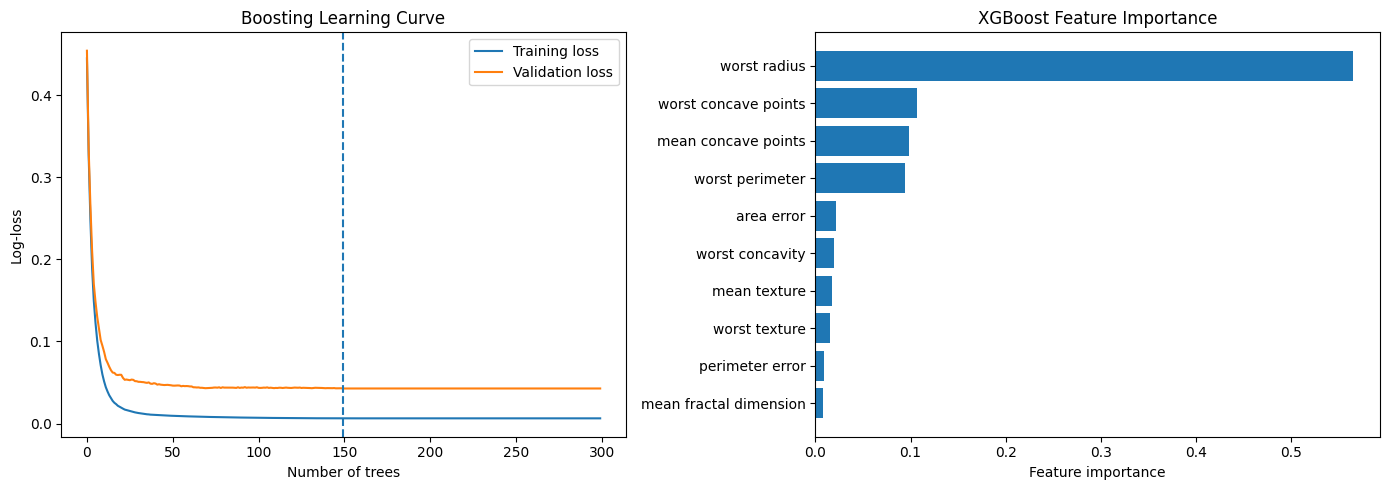

In [ ]:

# Practical 4(f): Gradient Boosting with XGBoost

import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import accuracy_score, roc_auc_score
from xgboost import XGBClassifier

# STEP 1: Load dataset and split into training, validation and test sets
data = load_breast_cancer()

X_tmp, X_test, y_tmp, y_test = train_test_split(
    data.data,
    data.target,
    test_size=0.2,
    random_state=2,
    stratify=data.target
)

X_train, X_val, y_train, y_val = train_test_split(
    X_tmp,
    y_tmp,
    test_size=0.25,
    random_state=2,
    stratify=y_tmp
)

print("Training samples:", len(X_train))
print("Validation samples:", len(X_val))
print("Test samples:", len(X_test))

# STEP 2: Train the baseline XGBoost model
base = XGBClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    eval_metric="logloss",
    random_state=0
)

base.fit(X_train, y_train)

print("\nBaseline -> validation accuracy = "
      f"{base.score(X_val, y_val):.4f}, "
      f"test accuracy = {base.score(X_test, y_test):.4f}")

# STEP 3: Tune hyperparameters using GridSearchCV
grid = {
    "max_depth": [2, 3, 5],
    "learning_rate": [0.03, 0.1, 0.3],
    "n_estimators": [50, 150],
    "subsample": [0.7, 1.0]
}

search = GridSearchCV(
    XGBClassifier(
        eval_metric="logloss",
        random_state=0
    ),
    grid,
    cv=3,
    scoring="accuracy",
    n_jobs=1
)

search.fit(X_tmp, y_tmp)

print("\nBest parameters:", search.best_params_)
print(f"Best CV accuracy: {search.best_score_:.4f}")

# STEP 4: Evaluate the tuned model on the untouched test set
best = search.best_estimator_

pred = best.predict(X_test)
proba = best.predict_proba(X_test)[:, 1]

print("\nTuned model test accuracy = "
      f"{accuracy_score(y_test, pred):.4f}")

print("ROC-AUC = "
      f"{roc_auc_score(y_test, proba):.4f}")

# STEP 5: Record training and validation loss after each tree
es = XGBClassifier(
    n_estimators=300,
    learning_rate=0.3,
    max_depth=4,
    eval_metric="logloss",
    random_state=0
)

es.fit(
    X_train,
    y_train,
    eval_set=[
        (X_train, y_train),
        (X_val, y_val)
    ],
    verbose=False
)

hist = es.evals_result()

train_loss = hist["validation_0"]["logloss"]
val_loss = hist["validation_1"]["logloss"]

best_round = int(np.argmin(val_loss)) + 1

print(f"\nValidation loss is lowest after {best_round} trees.")

# STEP 6: Find the top 10 important features
imp = best.feature_importances_
order = np.argsort(imp)[::-1][:10]

print("\nTop-10 features by importance:")

for i in order:
    print(f"{data.feature_names[i]:26s} {imp[i]:.4f}")

# STEP 7: Plot learning curve and feature importance
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

ax[0].plot(train_loss, label="Training loss")
ax[0].plot(val_loss, label="Validation loss")
ax[0].axvline(best_round - 1, linestyle="--")
ax[0].set_xlabel("Number of trees")
ax[0].set_ylabel("Log-loss")
ax[0].set_title("Boosting Learning Curve")
ax[0].legend()

ax[1].barh(
    [data.feature_names[i] for i in order][::-1],
    imp[order][::-1]
)
ax[1].set_xlabel("Feature importance")
ax[1].set_title("XGBoost Feature Importance")

plt.tight_layout()
plt.show()


In [ ]:

# Practical 5(a): Naive Bayes Classifier from Scratch

import pandas as pd
from sklearn.preprocessing import OrdinalEncoder
from sklearn.naive_bayes import CategoricalNB

# STEP 1: Create the PlayTennis dataset
rows = """Outlook,Temperature,Humidity,Wind,PlayTennis
Sunny,Hot,High,Weak,No
Sunny,Hot,High,Strong,No
Overcast,Hot,High,Weak,Yes
Rain,Mild,High,Weak,Yes
Rain,Cool,Normal,Weak,Yes
Rain,Cool,Normal,Strong,No
Overcast,Cool,Normal,Strong,Yes
Sunny,Mild,High,Weak,No
Sunny,Cool,Normal,Weak,Yes
Rain,Mild,Normal,Weak,Yes
Sunny,Mild,Normal,Strong,Yes
Overcast,Mild,High,Strong,Yes
Overcast,Hot,Normal,Weak,Yes
Rain,Mild,High,Strong,No
"""

with open("playtennis.csv", "w") as f:
    f.write(rows)

df = pd.read_csv("playtennis.csv")
print("PlayTennis Dataset:")
print(df, "\n")

target = "PlayTennis"
features = [c for c in df.columns if c != target]

# STEP 2: Calculate prior probabilities
priors = df[target].value_counts(normalize=True)

print("Prior probabilities:")
print(priors.round(4), "\n")

# STEP 3: Calculate likelihoods using Laplace smoothing
likelihood = {}

for feat in features:
    likelihood[feat] = {}
    values = df[feat].unique()

    for cls in priors.index:
        subset = df[df[target] == cls]

        for v in values:
            count = (subset[feat] == v).sum()

            likelihood[feat][(v, cls)] = (
                (count + 1) / (len(subset) + len(values))
            )

print("Example likelihoods:")
print("P(Outlook=Sunny | Yes) = %.4f"
      % likelihood["Outlook"][("Sunny", "Yes")])
print("P(Outlook=Sunny | No)  = %.4f"
      % likelihood["Outlook"][("Sunny", "No")])
print("P(Wind=Strong | Yes) = %.4f"
      % likelihood["Wind"][("Strong", "Yes")])
print("P(Wind=Strong | No)  = %.4f\n"
      % likelihood["Wind"][("Strong", "No")])

# STEP 4: Create the Naive Bayes classification function
def classify(sample):
    scores = {}

    for cls in priors.index:
        score = priors[cls]

        for feat in features:
            score *= likelihood[feat][(sample[feat], cls)]

        scores[cls] = score

    total = sum(scores.values())
    probs = {c: s / total for c, s in scores.items()}

    return max(probs, key=probs.get), scores, probs

# STEP 5: Classify a new sample
test = {
    "Outlook": "Sunny",
    "Temperature": "Cool",
    "Humidity": "High",
    "Wind": "Strong"
}

label, scores, probs = classify(test)

print("Test sample:", test)

for c in scores:
    print(f"Score({c}) = {scores[c]:.6f}")

print("Posterior probabilities:",
      {c: round(float(p), 4) for c, p in probs.items()})

print("PREDICTION -> PlayTennis =", label, "\n")

# STEP 6: Calculate training accuracy
hits = sum(
    classify(r[features].to_dict())[0] == r[target]
    for _, r in df.iterrows()
)

print("Training accuracy of scratch model: "
      f"{hits}/{len(df)} = {100 * hits / len(df):.1f}%")

# STEP 7: Verify with scikit-learn CategoricalNB
enc = OrdinalEncoder()
Xn = enc.fit_transform(df[features])

sk = CategoricalNB(alpha=1.0)
sk.fit(Xn, df[target])

xt = enc.transform(pd.DataFrame([test]))
prediction = sk.predict(xt)[0]

probabilities = {
    str(c): round(float(p), 4)
    for c, p in zip(sk.classes_, sk.predict_proba(xt)[0])
}

print("Scikit-learn prediction:", prediction)
print("Scikit-learn probabilities:", probabilities)


PlayTennis Dataset:
     Outlook Temperature Humidity    Wind PlayTennis
0      Sunny         Hot     High    Weak         No
1      Sunny         Hot     High  Strong         No
2   Overcast         Hot     High    Weak        Yes
3       Rain        Mild     High    Weak        Yes
4       Rain        Cool   Normal    Weak        Yes
5       Rain        Cool   Normal  Strong         No
6   Overcast        Cool   Normal  Strong        Yes
7      Sunny        Mild     High    Weak         No
8      Sunny        Cool   Normal    Weak        Yes
9       Rain        Mild   Normal    Weak        Yes
10     Sunny        Mild   Normal  Strong        Yes
11  Overcast        Mild     High  Strong        Yes
12  Overcast         Hot   Normal    Weak        Yes
13      Rain        Mild     High  Strong         No 

Prior probabilities:
PlayTennis
Yes    0.6429
No     0.3571
Name: proportion, dtype: float64 

Example likelihoods:
P(Outlook=Sunny | Yes) = 0.2500
P(Outlook=Sunny | No)  = 0.5000
P(W

In [ ]:

####INSTALL THIS FOR PRAC 5B
!pip install -q hmmlearn


Start probabilities: [0.6 0.4]
Transition matrix:
 [[0.7 0.3]
 [0.4 0.6]]
Emission matrix:
 [[0.1 0.4 0.5]
 [0.6 0.3 0.1]]

Observed activities: ['walk', 'clean', 'shop', 'clean', 'walk']
Most likely weather: ['Sunny', 'Rainy', 'Rainy', 'Rainy', 'Sunny']
Log-probability of path: -7.0741 (probability = 0.000847)
Likelihood of observations: 0.002856

Posterior probabilities:
 [[0.272 0.728]
 [0.834 0.166]
 [0.764 0.236]
 [0.831 0.169]
 [0.25  0.75 ]]

LEARNED transition matrix:
[[0.656 0.344]
 [0.429 0.571]]

LEARNED emission matrix:
[[0.032 0.45  0.517]
 [0.65  0.27  0.081]]

Hidden-state recovery accuracy: 79.1%

Learned regime means: [0.045 0.014]
Learned regime standard deviations: [0.393 1.506]

Learned transition matrix (calm, volatile order):
[[0.979 0.021]
 [0.076 0.924]]


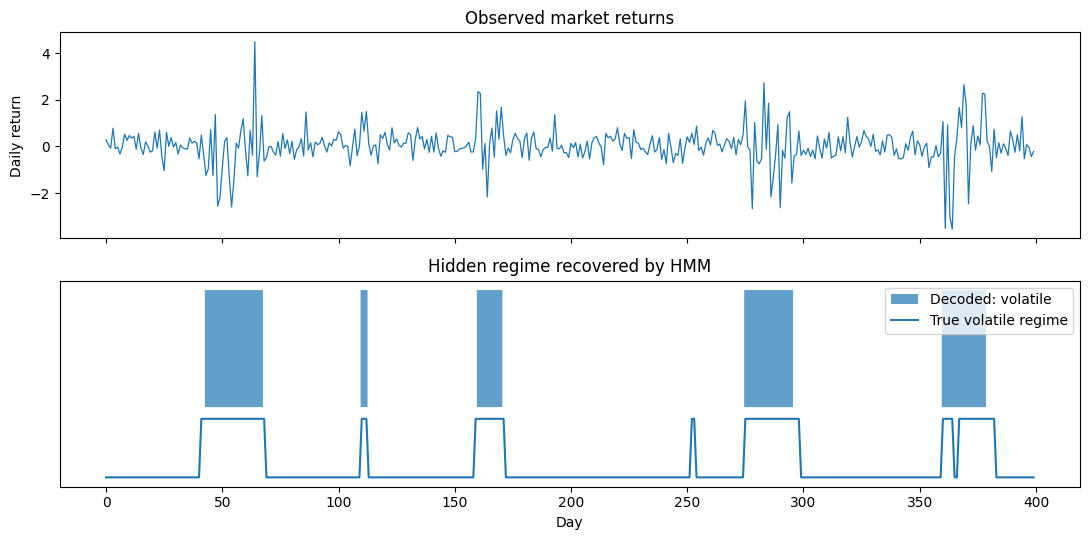

In [ ]:
########PRACTICAL 5B
import numpy as np
import matplotlib.pyplot as plt
from hmmlearn import hmm

np.set_printoptions(precision=3, suppress=True)

# =====================================================
# PART A: Build an HMM manually and decode observations
# =====================================================

states = ["Rainy", "Sunny"]
obs_names = ["walk", "shop", "clean"]

model = hmm.CategoricalHMM(
    n_components=2,
    random_state=0
)

# Initial state probabilities
model.startprob_ = np.array([0.6, 0.4])

# Transition probabilities
model.transmat_ = np.array([
    [0.7, 0.3],
    [0.4, 0.6]
])

# Observation probabilities
model.emissionprob_ = np.array([
    [0.1, 0.4, 0.5],
    [0.6, 0.3, 0.1]
])

print("Start probabilities:", model.startprob_)
print("Transition matrix:\n", model.transmat_)
print("Emission matrix:\n", model.emissionprob_)

# Observations: walk, clean, shop, clean, walk
seq = np.array([[0], [2], [1], [2], [0]])

print("\nObserved activities:",
      [obs_names[i] for i in seq.ravel()])

# Viterbi decoding
log_prob, path = model.decode(seq, algorithm="viterbi")

print("Most likely weather:",
      [states[i] for i in path])

print("Log-probability of path: %.4f (probability = %.6f)"
      % (log_prob, np.exp(log_prob)))

# Forward algorithm: likelihood of all observations
print("Likelihood of observations: %.6f"
      % np.exp(model.score(seq)))

# Posterior probability of each hidden state
print("\nPosterior probabilities:\n",
      model.predict_proba(seq))


# =====================================================
# PART B: Learn HMM parameters using Baum-Welch
# =====================================================

# Generate 3000 observations from the original model
X, true_states = model.sample(3000)

best_model = None
best_score = -np.inf

# Try 10 random initializations
for seed in range(10):
    candidate = hmm.CategoricalHMM(
        n_components=2,
        n_iter=300,
        tol=1e-5,
        random_state=seed
    )

    candidate.fit(X)
    score = candidate.score(X)

    if score > best_score:
        best_model = candidate
        best_score = score

learner = best_model

# Match learned states to the original state order
order_b = np.argsort(learner.emissionprob_[:, 0])

print("\nLEARNED transition matrix:")
print(learner.transmat_[np.ix_(order_b, order_b)])

print("\nLEARNED emission matrix:")
print(learner.emissionprob_[order_b])

# Decode hidden states using the learned model
pred = learner.predict(X)

# State labels can be swapped, so check both possibilities
accuracy = max(
    np.mean(pred == true_states.ravel()),
    np.mean(pred != true_states.ravel())
)

print("\nHidden-state recovery accuracy: %.1f%%"
      % (100 * accuracy))


# =====================================================
# PART C: Gaussian HMM - Calm and volatile market regimes
# =====================================================

rng = np.random.RandomState(1)

# Generate hidden regimes: 0 = calm, 1 = volatile
regime = np.zeros(400, dtype=int)

for t in range(1, 400):
    stay = 0.97 if regime[t - 1] == 0 else 0.92

    if rng.rand() < stay:
        regime[t] = regime[t - 1]
    else:
        regime[t] = 1 - regime[t - 1]

# Generate daily returns for each regime
returns = np.where(
    regime == 0,
    rng.normal(0.05, 0.4, 400),
    rng.normal(-0.1, 1.5, 400)
)

# Train Gaussian HMM
g = hmm.GaussianHMM(
    n_components=2,
    covariance_type="full",
    n_iter=300,
    random_state=0
)

g.fit(returns.reshape(-1, 1))

# Predict hidden market regimes
hidden = g.predict(returns.reshape(-1, 1))

# Sort states by variance: lower variance = calm
order = np.argsort(g.covars_.ravel())

print("\nLearned regime means:",
      g.means_.ravel()[order])

print("Learned regime standard deviations:",
      np.sqrt(g.covars_.ravel())[order])

print("\nLearned transition matrix (calm, volatile order):")
print(g.transmat_[np.ix_(order, order)])

# Plot observed returns and the decoded regimes
fig, ax = plt.subplots(2, 1, figsize=(11, 5.5), sharex=True)

ax[0].plot(returns, linewidth=0.9)
ax[0].set_ylabel("Daily return")
ax[0].set_title("Observed market returns")

calm_label = order[0]

ax[1].fill_between(
    range(400),
    0,
    (hidden != calm_label).astype(int),
    step="mid",
    alpha=0.7,
    label="Decoded: volatile"
)

ax[1].plot(
    (regime == 1).astype(int) * 0.5 - 0.6,
    label="True volatile regime"
)

ax[1].set_yticks([])
ax[1].set_xlabel("Day")
ax[1].legend(loc="upper right")
ax[1].set_title("Hidden regime recovered by HMM")

plt.tight_layout()
plt.show()


After  0 points: mean intercept =  0.000 (sd 0.707) | mean slope =  0.000 (sd 0.707)
After  1 points: mean intercept =  0.160 (sd 0.494) | mean slope =  0.149 (sd 0.526)
After  3 points: mean intercept = -0.222 (sd 0.202) | mean slope =  0.368 (sd 0.260)
After 10 points: mean intercept = -0.265 (sd 0.065) | mean slope =  0.547 (sd 0.095)
After 30 points: mean intercept = -0.284 (sd 0.037) | mean slope =  0.541 (sd 0.055)
True values: intercept = -0.300 | slope = 0.500



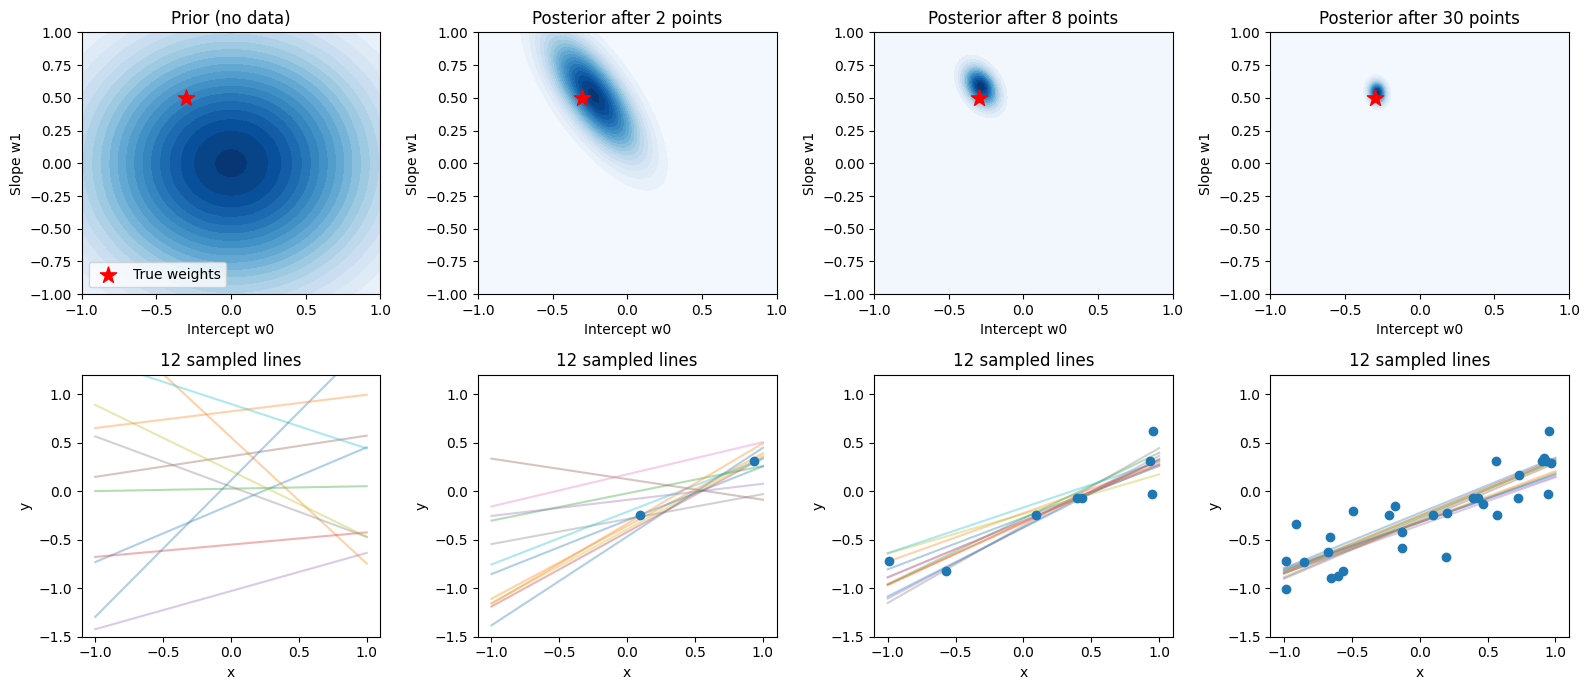

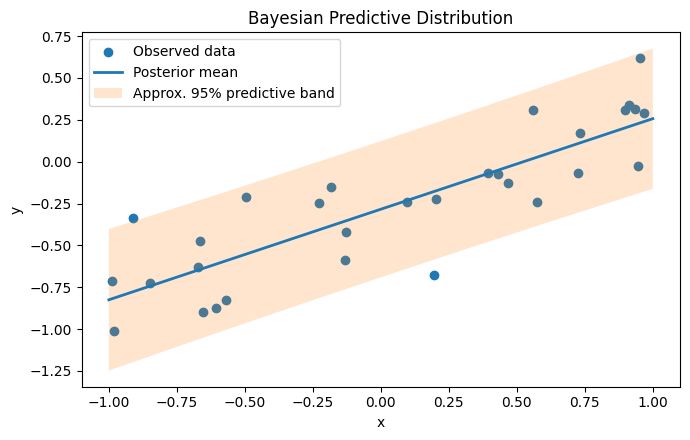

BayesianRidge intercept = -0.285, slope = 0.538
Prediction at x = 0.5: -0.016 +/- 0.223


In [ ]:
#########PRACTICAL 6A
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import BayesianRidge

rng = np.random.RandomState(4)

# STEP 1: Generate data from the true line
w_true = np.array([-0.3, 0.5])
sigma = 0.2

x = rng.uniform(-1, 1, 30)
y = w_true[0] + w_true[1] * x + rng.normal(0, sigma, 30)

# Design matrix: intercept and input
Phi = np.c_[np.ones_like(x), x]

# STEP 2: Define prior
alpha = 2.0
beta = 1.0 / sigma**2

prior_mean = np.zeros(2)
prior_cov = np.eye(2) / alpha

# STEP 3: Calculate posterior mean and covariance
def posterior(n):
    P = Phi[:n]
    t = y[:n]

    S_inv = alpha * np.eye(2) + beta * (P.T @ P)
    S = np.linalg.inv(S_inv)
    m = beta * S @ P.T @ t

    return m, S

# Print posterior after different amounts of data
for n in [0, 1, 3, 10, 30]:
    if n == 0:
        m, S = prior_mean, prior_cov
    else:
        m, S = posterior(n)

    print(
        "After %2d points: mean intercept = %6.3f (sd %.3f) | "
        "mean slope = %6.3f (sd %.3f)"
        % (n, m[0], np.sqrt(S[0, 0]),
           m[1], np.sqrt(S[1, 1]))
    )

print("True values: intercept = %.3f | slope = %.3f\n"
      % tuple(w_true))

# STEP 4: Plot prior and posterior distributions
w0, w1 = np.meshgrid(
    np.linspace(-1, 1, 120),
    np.linspace(-1, 1, 120)
)

grid = np.dstack([w0, w1])

def gauss_density(m, S):
    d = grid - m
    Sinv = np.linalg.inv(S)

    expo = -0.5 * np.einsum(
        "...i,ij,...j->...", d, Sinv, d
    )

    return np.exp(expo) / (
        2 * np.pi * np.sqrt(np.linalg.det(S))
    )

counts = [0, 2, 8, 30]
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
xs = np.linspace(-1, 1, 50)

for j, n in enumerate(counts):
    if n == 0:
        m, S = prior_mean, prior_cov
    else:
        m, S = posterior(n)

    axes[0, j].contourf(
        w0, w1, gauss_density(m, S),
        levels=20, cmap="Blues"
    )

    axes[0, j].scatter(
        *w_true, color="red", marker="*", s=150,
        label="True weights"
    )

    axes[0, j].set_title(
        "Prior (no data)" if n == 0
        else "Posterior after %d points" % n
    )
    axes[0, j].set_xlabel("Intercept w0")
    axes[0, j].set_ylabel("Slope w1")

    # Sample 12 possible regression lines
    samples = rng.multivariate_normal(m, S, 12)

    for w in samples:
        axes[1, j].plot(
            xs, w[0] + w[1] * xs,
            alpha=0.35
        )

    axes[1, j].scatter(x[:n], y[:n], zorder=3)
    axes[1, j].set_ylim(-1.5, 1.2)
    axes[1, j].set_xlabel("x")
    axes[1, j].set_ylabel("y")
    axes[1, j].set_title("12 sampled lines")

axes[0, 0].legend(loc="lower left")
plt.tight_layout()
plt.show()

# STEP 5: Predictive distribution with uncertainty band
m, S = posterior(30)
Phi_new = np.c_[np.ones_like(xs), xs]

pred_mean = Phi_new @ m
pred_var = 1 / beta + np.sum(
    (Phi_new @ S) * Phi_new, axis=1
)
pred_sd = np.sqrt(pred_var)

plt.figure(figsize=(7, 4.5))
plt.scatter(x, y, label="Observed data")
plt.plot(xs, pred_mean, linewidth=2, label="Posterior mean")
plt.fill_between(
    xs,
    pred_mean - 2 * pred_sd,
    pred_mean + 2 * pred_sd,
    alpha=0.2,
    label="Approx. 95% predictive band"
)

plt.xlabel("x")
plt.ylabel("y")
plt.title("Bayesian Predictive Distribution")
plt.legend()
plt.tight_layout()
plt.show()

# STEP 6: Compare with scikit-learn BayesianRidge
br = BayesianRidge(fit_intercept=True)
br.fit(x.reshape(-1, 1), y)

print("BayesianRidge intercept = %.3f, slope = %.3f"
      % (br.intercept_, br.coef_[0]))

pm, ps = br.predict(
    np.array([[0.5]]),
    return_std=True
)

print("Prediction at x = 0.5: %.3f +/- %.3f"
      % (pm[0], ps[0]))


Components       BIC          AIC
    1          5937.5       5915.6
    2          5284.1       5235.8
    3          4968.6       4893.9
    4          5007.5       4906.3
    5          5036.0       4908.5
    6          5066.3       4912.4

Best number of components by BIC: 3

Mixing weights: [0.331 0.334 0.335]
Means:
 [[ 8.81  6.21]
 [ 1.13  4.82]
 [-0.03  0.  ]]
Covariance of component 0:
 [[1.7  0.73]
 [0.73 0.67]]
EM converged: True in 4 iterations

Soft assignment of first 3 points:
 [[0.999 0.001 0.   ]
 [0.    0.    1.   ]
 [0.    1.    0.   ]]
Lowest-density point: index 145 -> [5.41 3.34]
New point: [2. 3.]
Cluster probabilities: [0.    0.805 0.195]

Adjusted Rand Index (1.0 = perfect match)
GMM     : 0.99
K-Means : 0.899


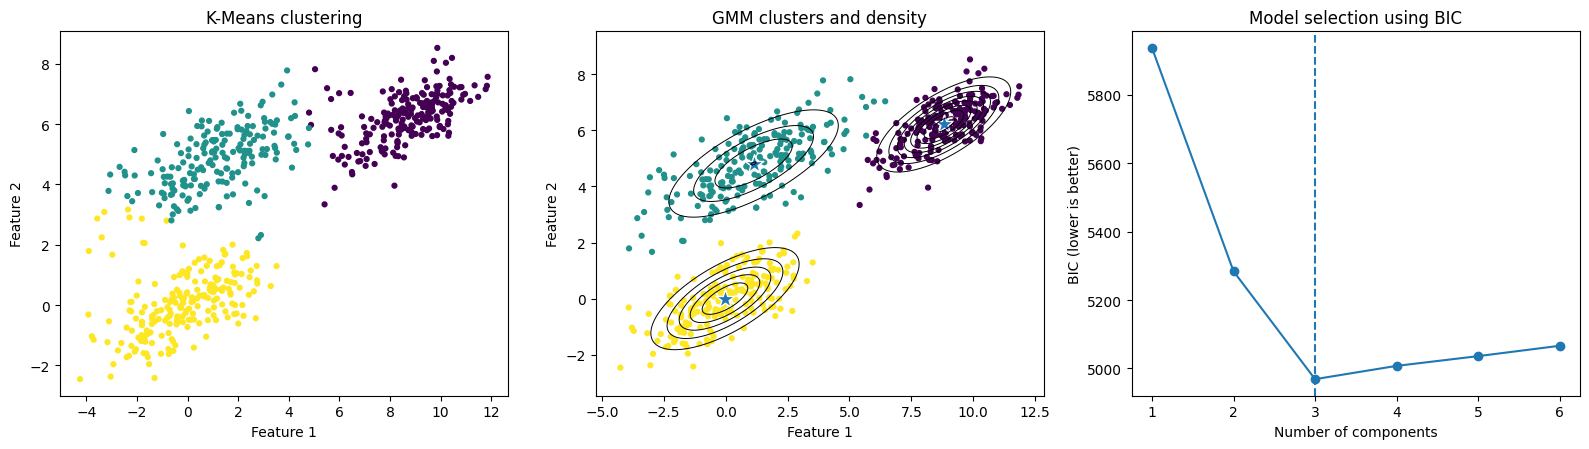

In [ ]:
############PRACTICAL 6B
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import make_blobs
from sklearn.mixture import GaussianMixture
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score

# STEP 1: Generate three clusters
X, y_true = make_blobs(
    n_samples=600,
    centers=[[0, 0], [5, 4], [0, 6]],
    cluster_std=[1.0, 0.8, 1.2],
    random_state=11
)

# Stretch clusters into elliptical shapes
stretch = np.array([
    [1.6, 0.6],
    [0.2, 0.8]
])

X = X @ stretch

# STEP 2: Select the number of components using BIC
print("Components       BIC          AIC")

bics = []
aics = []

for k in range(1, 7):
    g = GaussianMixture(
        n_components=k,
        covariance_type="full",
        random_state=0
    ).fit(X)

    bic = g.bic(X)
    aic = g.aic(X)

    bics.append(bic)
    aics.append(aic)

    print("%5d       %9.1f    %9.1f" % (k, bic, aic))

best_k = int(np.argmin(bics)) + 1
print("\nBest number of components by BIC:", best_k)

# STEP 3: Fit the final GMM
gmm = GaussianMixture(
    n_components=best_k,
    covariance_type="full",
    random_state=0
).fit(X)

print("\nMixing weights:", gmm.weights_.round(3))
print("Means:\n", gmm.means_.round(2))
print("Covariance of component 0:\n",
      gmm.covariances_[0].round(2))

print("EM converged:", gmm.converged_,
      "in", gmm.n_iter_, "iterations")

# STEP 4: Hard labels, soft probabilities and density
labels = gmm.predict(X)
probs = gmm.predict_proba(X)
dens = gmm.score_samples(X)

print("\nSoft assignment of first 3 points:\n",
      probs[:3].round(3))

idx = int(np.argmin(dens))
print("Lowest-density point: index", idx,
      "->", X[idx].round(2))

new_point = np.array([[2.0, 3.0]])
print("New point:", new_point[0])
print("Cluster probabilities:",
      gmm.predict_proba(new_point).round(3)[0])

# STEP 5: Compare GMM with K-Means
km = KMeans(
    n_clusters=best_k,
    n_init=10,
    random_state=0
).fit(X)

print("\nAdjusted Rand Index (1.0 = perfect match)")
print("GMM     :", round(adjusted_rand_score(y_true, labels), 3))
print("K-Means :", round(adjusted_rand_score(y_true, km.labels_), 3))

# STEP 6: Create density contours
xx, yy = np.meshgrid(
    np.linspace(X[:, 0].min() - 1, X[:, 0].max() + 1, 250),
    np.linspace(X[:, 1].min() - 1, X[:, 1].max() + 1, 250)
)

zz = np.exp(
    gmm.score_samples(
        np.c_[xx.ravel(), yy.ravel()]
    )
).reshape(xx.shape)

# Plot 1: K-Means
fig, ax = plt.subplots(1, 3, figsize=(16, 4.6))

ax[0].scatter(
    X[:, 0], X[:, 1],
    c=km.labels_, cmap="viridis", s=12
)
ax[0].set_title("K-Means clustering")
ax[0].set_xlabel("Feature 1")
ax[0].set_ylabel("Feature 2")

# Plot 2: GMM clusters and density contours
ax[1].scatter(
    X[:, 0], X[:, 1],
    c=labels, cmap="viridis", s=12
)

ax[1].contour(
    xx, yy, zz, levels=8,
    colors="black", linewidths=0.7
)

ax[1].scatter(
    *gmm.means_.T,
    marker="*", s=200,
    edgecolor="white"
)

ax[1].set_title("GMM clusters and density")
ax[1].set_xlabel("Feature 1")
ax[1].set_ylabel("Feature 2")

# Plot 3: BIC curve
ax[2].plot(range(1, 7), bics, "o-")
ax[2].axvline(best_k, linestyle="--")
ax[2].set_xlabel("Number of components")
ax[2].set_ylabel("BIC (lower is better)")
ax[2].set_title("Model selection using BIC")

plt.tight_layout()
plt.show()


Why not use only one split?
Split seed 0: accuracy = 0.978
Split seed 1: accuracy = 0.956
Split seed 2: accuracy = 0.978
Split seed 3: accuracy = 0.978
Split seed 4: accuracy = 0.956

K-Fold scores: [0.967 0.967 0.967 0.933 0.933]
K-Fold mean accuracy: 0.9533
K-Fold standard deviation: 0.0163

Stratified K-Fold scores: [0.967 1.    0.967 1.    0.9  ]
Stratified mean accuracy: 0.9667

Class counts in each stratified test fold:
Fold 1: [10 10 10]
Fold 2: [10 10 10]
Fold 3: [10 10 10]
Fold 4: [10 10 10]
Fold 5: [10 10 10]

Repeated Stratified K-Fold
Mean accuracy: 0.9583
Standard deviation: 0.0314
Number of scores: 20

Leave-One-Out mean accuracy: 0.9533

Shuffle-Split mean accuracy: 0.9733
Shuffle-Split standard deviation: 0.0166

Multi-metric results:
train_accuracy: 0.9700
test_accuracy: 0.9667
test_f1_macro: 0.9666
test_precision_macro: 0.9684
test_recall_macro: 0.9667

Imbalanced dataset class counts: [178  22]
Positive cases in ordinary K-Fold:
[3, 5, 5, 5, 4]
Positive cases in Stra

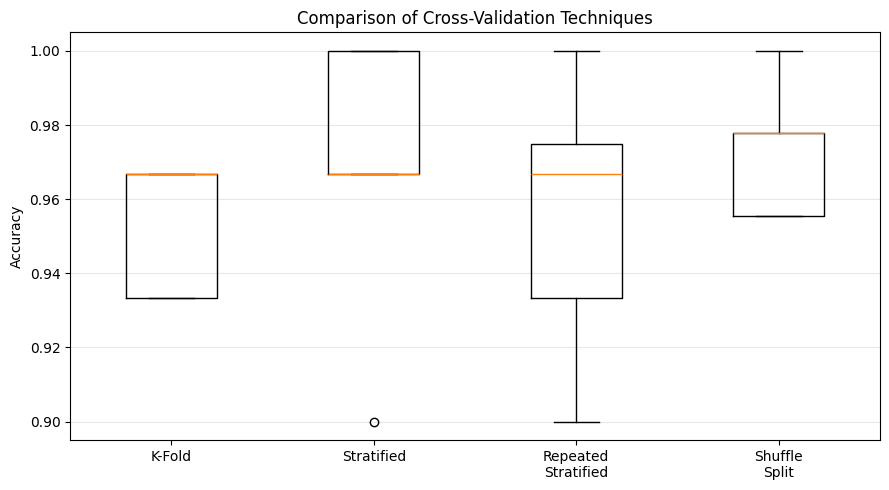

In [ ]:

# PRACTICAL 7(a): CROSS-VALIDATION TECHNIQUES

import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris, make_classification
from sklearn.model_selection import (
    KFold,
    StratifiedKFold,
    RepeatedStratifiedKFold,
    LeaveOneOut,
    ShuffleSplit,
    cross_val_score,
    cross_validate,
    train_test_split
)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# STEP 1: Load dataset and create model pipeline
X, y = load_iris(return_X_y=True)

model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=500)
)

# Show how results change with different train-test splits
print("Why not use only one split?")

for seed in [0, 1, 2, 3, 4]:
    Xa, Xb, ya, yb = train_test_split(
        X, y, test_size=0.3, random_state=seed
    )
    model.fit(Xa, ya)
    print(f"Split seed {seed}: accuracy = {model.score(Xb, yb):.3f}")

# STEP 2: K-Fold Cross-Validation
kf = KFold(n_splits=5, shuffle=True, random_state=1)

scores_kf = cross_val_score(model, X, y, cv=kf)

print("\nK-Fold scores:", scores_kf.round(3))
print("K-Fold mean accuracy:", round(scores_kf.mean(), 4))
print("K-Fold standard deviation:", round(scores_kf.std(), 4))

# STEP 3: Stratified K-Fold
skf = StratifiedKFold(
    n_splits=5, shuffle=True, random_state=1
)

scores_skf = cross_val_score(model, X, y, cv=skf)

print("\nStratified K-Fold scores:", scores_skf.round(3))
print("Stratified mean accuracy:", round(scores_skf.mean(), 4))

print("\nClass counts in each stratified test fold:")
for i, (train_index, test_index) in enumerate(
    skf.split(X, y), start=1
):
    print(f"Fold {i}:", np.bincount(y[test_index]))

# STEP 4: Repeated Stratified K-Fold
rskf = RepeatedStratifiedKFold(
    n_splits=5, n_repeats=4, random_state=1
)

scores_rep = cross_val_score(model, X, y, cv=rskf)

print("\nRepeated Stratified K-Fold")
print("Mean accuracy:", round(scores_rep.mean(), 4))
print("Standard deviation:", round(scores_rep.std(), 4))
print("Number of scores:", len(scores_rep))

# STEP 5: Leave-One-Out
scores_loo = cross_val_score(
    model, X, y, cv=LeaveOneOut()
)

print("\nLeave-One-Out mean accuracy:",
      round(scores_loo.mean(), 4))

# STEP 6: Shuffle-Split
ss = ShuffleSplit(
    n_splits=10, test_size=0.3, random_state=1
)

scores_ss = cross_val_score(model, X, y, cv=ss)

print("\nShuffle-Split mean accuracy:",
      round(scores_ss.mean(), 4))
print("Shuffle-Split standard deviation:",
      round(scores_ss.std(), 4))

# STEP 7: Calculate multiple evaluation metrics
res = cross_validate(
    model, X, y,
    cv=skf,
    scoring=[
        "accuracy",
        "f1_macro",
        "precision_macro",
        "recall_macro"
    ],
    return_train_score=True
)

print("\nMulti-metric results:")
for key in [
    "train_accuracy",
    "test_accuracy",
    "test_f1_macro",
    "test_precision_macro",
    "test_recall_macro"
]:
    print(f"{key}: {res[key].mean():.4f}")

# STEP 8: Show why stratification matters
Xi, yi = make_classification(
    n_samples=200,
    weights=[0.9, 0.1],
    n_features=6,
    random_state=0
)

print("\nImbalanced dataset class counts:", np.bincount(yi))

print("Positive cases in ordinary K-Fold:")
print([
    int(yi[test_index].sum())
    for _, test_index in KFold(n_splits=5).split(Xi)
])

print("Positive cases in Stratified K-Fold:")
print([
    int(yi[test_index].sum())
    for _, test_index in StratifiedKFold(n_splits=5).split(Xi, yi)
])

# STEP 9: Plot cross-validation scores
plt.figure(figsize=(9, 5))

plt.boxplot([
    scores_kf,
    scores_skf,
    scores_rep,
    scores_ss
])

plt.xticks(
    [1, 2, 3, 4],
    ["K-Fold", "Stratified", "Repeated\nStratified", "Shuffle\nSplit"]
)

plt.ylabel("Accuracy")
plt.title("Comparison of Cross-Validation Techniques")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


Default SVM test accuracy: 0.958

GRID SEARCH
Combinations: 32
Total fits: 160
Time taken: 6.72 seconds
Best parameters: {'svm__C': 0.1, 'svm__gamma': 0.001, 'svm__kernel': 'linear'}
Best cross-validation accuracy: 0.9883
Test accuracy: 0.958

RANDOMIZED SEARCH
Number of trials: 20
Total fits: 100
Time taken: 2.16 seconds
Best parameters: {'svm__C': np.float64(0.210270361099893), 'svm__gamma': np.float64(0.12500712230836253), 'svm__kernel': 'linear'}
Best cross-validation accuracy: 0.9883
Test accuracy: 0.951

Top 6 Grid Search combinations:
 param_svm__C  param_svm__gamma param_svm__kernel  mean_train_score  mean_test_score  rank_test_score
          0.1             0.001            linear            0.9906           0.9883                1
          0.1             0.010            linear            0.9906           0.9883                1
          0.1             1.000            linear            0.9906           0.9883                1
          0.1             0.100            l

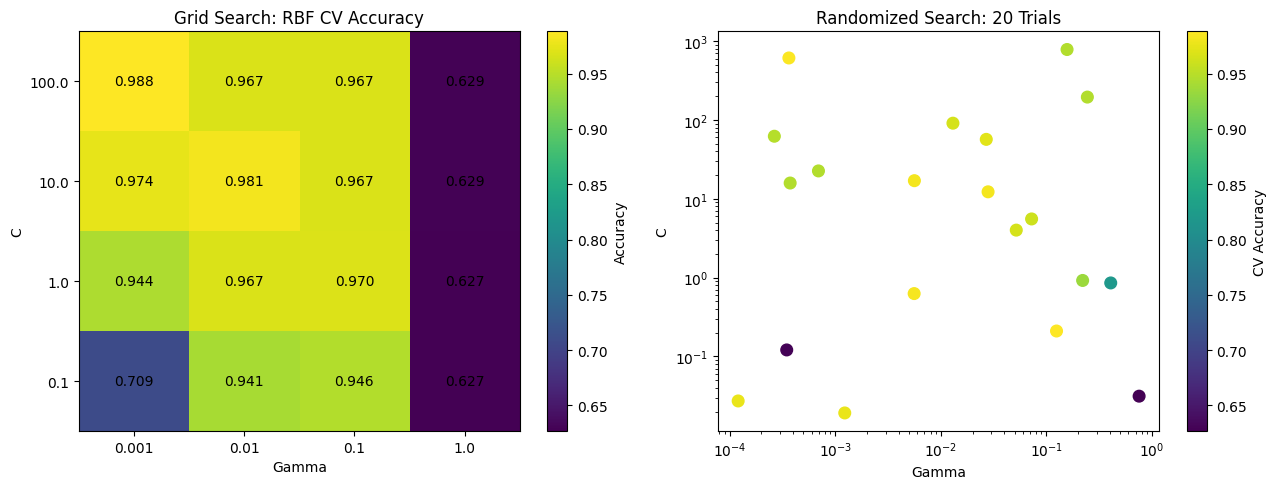

In [ ]:

# PRACTICAL 7(b): HYPERPARAMETER TUNING
# GRID SEARCH AND RANDOMIZED SEARCH

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import loguniform

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import (
    train_test_split,
    GridSearchCV,
    RandomizedSearchCV
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

# STEP 1: Load dataset and split into training and testing sets
X, y = load_breast_cancer(return_X_y=True)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,
    random_state=0,
    stratify=y
)

# Create a pipeline containing scaling and SVM
pipe = Pipeline([
    ("scale", StandardScaler()),
    ("svm", SVC())
])

# Check default SVM accuracy
pipe.fit(X_train, y_train)

print("Default SVM test accuracy:",
      round(pipe.score(X_test, y_test), 4))

# STEP 2: GRID SEARCH
# Try every combination of the specified parameters
grid = {
    "svm__C": [0.1, 1, 10, 100],
    "svm__gamma": [0.001, 0.01, 0.1, 1],
    "svm__kernel": ["rbf", "linear"]
}

gs = GridSearchCV(
    pipe,
    param_grid=grid,
    cv=5,
    scoring="accuracy",
    n_jobs=-1,
    return_train_score=True
)

start = time.time()
gs.fit(X_train, y_train)
grid_time = time.time() - start

print("\nGRID SEARCH")
print("Combinations:", len(gs.cv_results_["params"]))
print("Total fits:", len(gs.cv_results_["params"]) * 5)
print("Time taken:", round(grid_time, 2), "seconds")
print("Best parameters:", gs.best_params_)
print("Best cross-validation accuracy:", round(gs.best_score_, 4))
print("Test accuracy:", round(gs.score(X_test, y_test), 4))

# STEP 3: RANDOMIZED SEARCH
# Try 20 randomly selected parameter combinations
distributions = {
    "svm__C": loguniform(1e-2, 1e3),
    "svm__gamma": loguniform(1e-4, 1e0),
    "svm__kernel": ["rbf", "linear"]
}

rs = RandomizedSearchCV(
    pipe,
    param_distributions=distributions,
    n_iter=20,
    cv=5,
    scoring="accuracy",
    n_jobs=-1,
    random_state=0
)

start = time.time()
rs.fit(X_train, y_train)
random_time = time.time() - start

print("\nRANDOMIZED SEARCH")
print("Number of trials:", 20)
print("Total fits:", 20 * 5)
print("Time taken:", round(random_time, 2), "seconds")
print("Best parameters:", rs.best_params_)
print("Best cross-validation accuracy:", round(rs.best_score_, 4))
print("Test accuracy:", round(rs.score(X_test, y_test), 4))

# STEP 4: Display the top six Grid Search results
results = pd.DataFrame(gs.cv_results_)

columns = [
    "param_svm__C",
    "param_svm__gamma",
    "param_svm__kernel",
    "mean_train_score",
    "mean_test_score",
    "rank_test_score"
]

print("\nTop 6 Grid Search combinations:")
print(
    results.sort_values("rank_test_score")[columns]
    .head(6)
    .round(4)
    .to_string(index=False)
)

# STEP 5: Plot Grid Search heatmap and Randomized Search results
rbf_results = results[
    results["param_svm__kernel"] == "rbf"
]

table = rbf_results.pivot_table(
    index="param_svm__C",
    columns="param_svm__gamma",
    values="mean_test_score"
)

fig, ax = plt.subplots(1, 2, figsize=(13, 5))

# Grid Search heatmap
im = ax[0].imshow(
    table.values,
    aspect="auto",
    origin="lower"
)

ax[0].set_xticks(range(len(table.columns)))
ax[0].set_xticklabels(table.columns)
ax[0].set_yticks(range(len(table.index)))
ax[0].set_yticklabels(table.index)

for i in range(table.shape[0]):
    for j in range(table.shape[1]):
        ax[0].text(
            j, i,
            f"{table.values[i, j]:.3f}",
            ha="center",
            va="center"
        )

ax[0].set_xlabel("Gamma")
ax[0].set_ylabel("C")
ax[0].set_title("Grid Search: RBF CV Accuracy")
fig.colorbar(im, ax=ax[0], label="Accuracy")

# Randomized Search scatter plot
random_results = pd.DataFrame(rs.cv_results_)

scatter = ax[1].scatter(
    random_results["param_svm__gamma"].astype(float),
    random_results["param_svm__C"].astype(float),
    c=random_results["mean_test_score"],
    s=70
)

ax[1].set_xscale("log")
ax[1].set_yscale("log")
ax[1].set_xlabel("Gamma")
ax[1].set_ylabel("C")
ax[1].set_title("Randomized Search: 20 Trials")

fig.colorbar(scatter, ax=ax[1], label="CV Accuracy")

plt.tight_layout()
plt.show()


PART A - Medical Test
P(positive) = 0.059
P(disease | positive) = 0.161
After a SECOND positive test: 0.7848

PART B - Coin Bias (true theta = 0.7 )
Flips | Heads | Posterior Mean | 95% Credible Interval
    0 |     0 | 0.5000 | [0.094, 0.906]
    5 |     3 | 0.5556 | [0.245, 0.843]
   20 |    17 | 0.7917 | [0.612, 0.925]
  100 |    79 | 0.7788 | [0.695, 0.853]


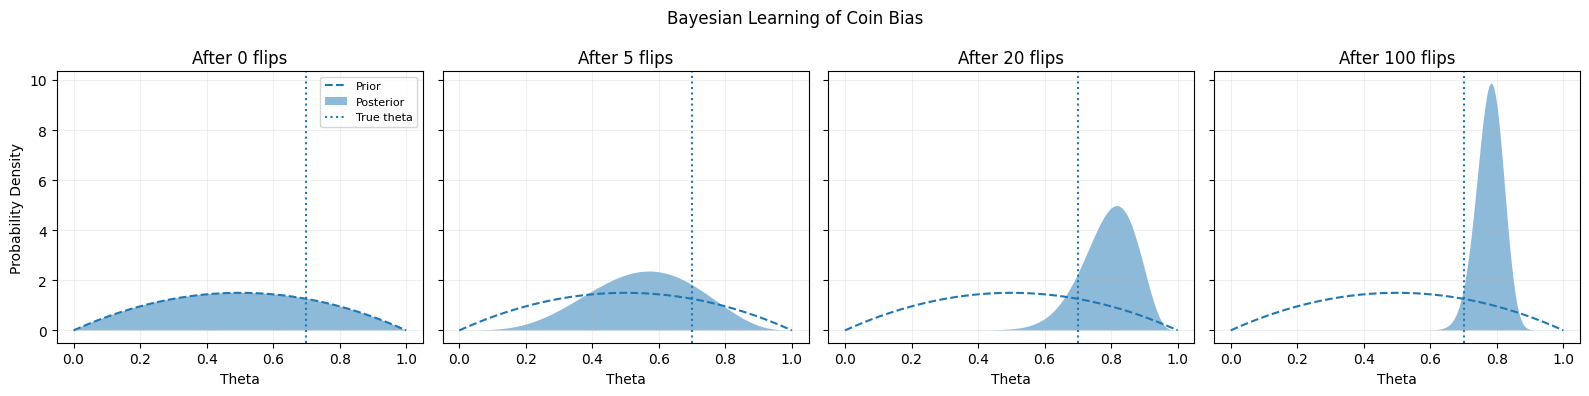

Posterior predictive P(next flip = heads): 0.7788

PART C - Unknown Mean Height
n | Sample Mean | Posterior Mean | Posterior SD
 0 |        0.00 |         160.00 |        15.00
 1 |      178.14 |         172.56 |         8.32
 5 |      174.13 |         172.98 |         4.29
25 |      170.61 |         170.42 |         1.98

PART D - Three Flips, All Heads
MLE = 1.0
MAP = 0.8
Posterior Mean = 0.714


In [ ]:

# PRACTICAL 8(a): BAYESIAN LEARNING USING INFERENCE

import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

# --------------------------------------------------
# PART A: BAYES' THEOREM - MEDICAL TEST
# --------------------------------------------------

# 1% of people have a disease.
# Sensitivity = 95%, false positive rate = 5%.

p_disease = 0.01
sens = 0.95
fpr = 0.05

# Probability of getting a positive test
p_pos = sens * p_disease + fpr * (1 - p_disease)

# Bayes' theorem
posterior = sens * p_disease / p_pos

print("PART A - Medical Test")
print("P(positive) =", round(p_pos, 4))
print("P(disease | positive) =", round(posterior, 4))

# Update belief after a second positive test
second = sens * posterior / (
    sens * posterior + fpr * (1 - posterior)
)

print("After a SECOND positive test:", round(second, 4))


# --------------------------------------------------
# PART B: LEARNING THE BIAS OF A COIN
# Beta prior + Binomial data
# --------------------------------------------------

true_theta = 0.7
rng = np.random.RandomState(3)

# Generate 100 coin flips
flips = rng.rand(100) < true_theta

# Initial Beta prior
a, b = 2, 2

print("\nPART B - Coin Bias (true theta =", true_theta, ")")
print("Flips | Heads | Posterior Mean | 95% Credible Interval")

stages = [0, 5, 20, 100]
fig, axes = plt.subplots(1, 4, figsize=(16, 4), sharey=True)

x = np.linspace(0, 1, 400)

for ax, n in zip(axes, stages):
    h = int(flips[:n].sum())
    t = n - h

    # Posterior distribution
    post = stats.beta(a + h, b + t)

    # 95% credible interval
    lo, hi = post.interval(0.95)

    print(
        f"{n:5d} | {h:5d} | {post.mean():.4f} | "
        f"[{lo:.3f}, {hi:.3f}]"
    )

    # Plot prior and posterior
    ax.plot(
        x, stats.beta(a, b).pdf(x),
        "--", label="Prior"
    )

    ax.fill_between(
        x, post.pdf(x),
        alpha=0.5, label="Posterior"
    )

    ax.axvline(true_theta, linestyle=":", label="True theta")
    ax.set_title(f"After {n} flips")
    ax.set_xlabel("Theta")
    ax.grid(alpha=0.2)

axes[0].set_ylabel("Probability Density")
axes[0].legend(fontsize=8)

plt.suptitle("Bayesian Learning of Coin Bias")
plt.tight_layout()
plt.show()

# Predict probability of the next flip being heads
h = int(flips.sum())
t = 100 - h

p_next = (a + h) / (a + b + h + t)

print("Posterior predictive P(next flip = heads):",
      round(p_next, 4))


# --------------------------------------------------
# PART C: GAUSSIAN INFERENCE - UNKNOWN MEAN
# --------------------------------------------------

sigma = 10.0
mu_true = 172.0

# Generate 25 height measurements
data = rng.normal(mu_true, sigma, 25)

# Prior distribution for the mean
mu0 = 160.0
tau0 = 15.0

print("\nPART C - Unknown Mean Height")
print("n | Sample Mean | Posterior Mean | Posterior SD")

for n in [0, 1, 5, 25]:

    xbar = data[:n].mean() if n > 0 else 0.0

    # Posterior precision
    prec = 1 / tau0**2 + n / sigma**2

    # Posterior mean
    mean = (
        mu0 / tau0**2 + n * xbar / sigma**2
    ) / prec

    # Posterior standard deviation
    post_sd = np.sqrt(1 / prec)

    print(
        f"{n:2d} | {xbar:11.2f} | "
        f"{mean:14.2f} | {post_sd:12.2f}"
    )


# --------------------------------------------------
# PART D: MLE VS MAP
# Three flips, all heads
# --------------------------------------------------

h3 = 3
n3 = 3

# Maximum Likelihood Estimate
mle = h3 / n3

# Maximum A Posteriori estimate
map_estimate = (a + h3 - 1) / (a + b + n3 - 2)

# Posterior mean
posterior_mean = (a + h3) / (a + b + n3)

print("\nPART D - Three Flips, All Heads")
print("MLE =", round(mle, 3))
print("MAP =", round(map_estimate, 3))
print("Posterior Mean =", round(posterior_mean, 3))


Real data shape: (1797, 64)
Each image contains 64 pixel values.

GENERATOR MODEL


Model: "generator"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_6 (Dense)                 │ (None, 64)             │         2,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 128)            │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 64)             │         8,256 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 18,688 (73.00 KB)

 Trainable params: 18,688 (73.00 KB)

...

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_9 (Dense)                 │ (None, 128)            │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 16,641 (65.00 KB)

 Trainable params: 16,641 (65.00 KB)

 Non-trainable params: 0 (0.00 B)


Training for 6000 steps...
Step    0 | D loss 1.524 | G loss 0.889 | D(real) 0.37 | D(fake) 0.41
Step  500 | D loss 1.334 | G loss 1.145 | D(real) 0.50 | D(fake) 0.32
Step 1000 | D loss 1.365 | G loss 0.976 | D(real) 0.45 | D(fake) 0.38
Step 1500 | D loss 1.442 | G loss 0.887 | D(real) 0.43 | D(fake) 0.42
Step 2000 | D loss 1.256 | G loss 0.858 | D(real) 0.51 | D(fake) 0.43
Step 2500 | D loss 1.316 | G loss 0.892 | D(real) 0.48 | D(fake) 0.41
Step 3000 | D loss 1.340 | G loss 0.853 | D(real) 0.48 | D(fake) 0.43
Step 3500 | D loss 1.303 | G loss 0.871 | D(real) 0.49 | D(fake) 0.42
Step 4000 | D loss 1.319 | G loss 0.851 | D(real) 0.50 | D(fake) 0.43
Step 4500 | D loss 1.238 | G loss 0.882 | D(real) 0.54 | D(fake) 0.42
Step 5000 | D loss 1.308 | G loss 0.946 | D(real) 0.46 | D(fake) 0.39
Step 5500 | D loss 1.323 | G loss 0.915 | D(real) 0.49 | D(fake) 0.41
Step 6000 | D loss 1.300 | G loss 0.900 | D(real) 0.52 | D(fake) 0.41


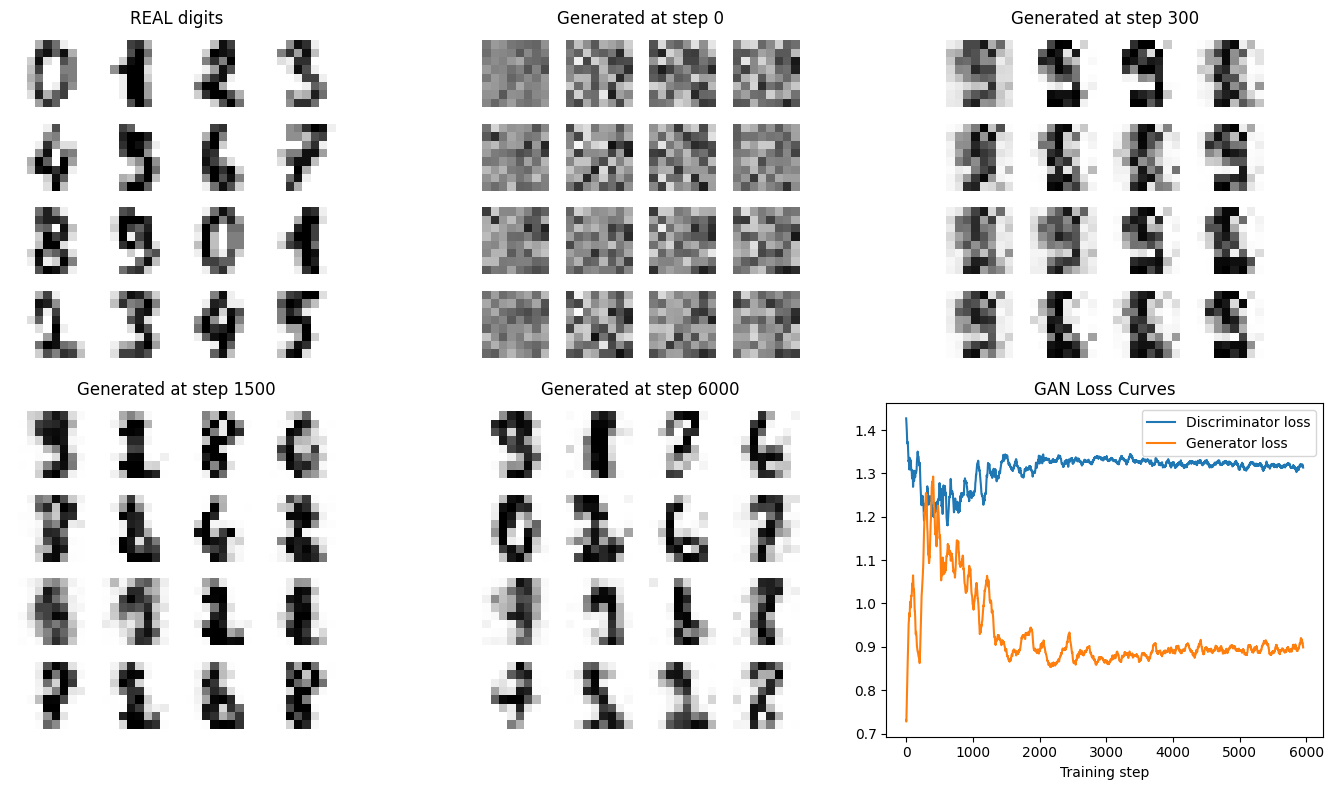

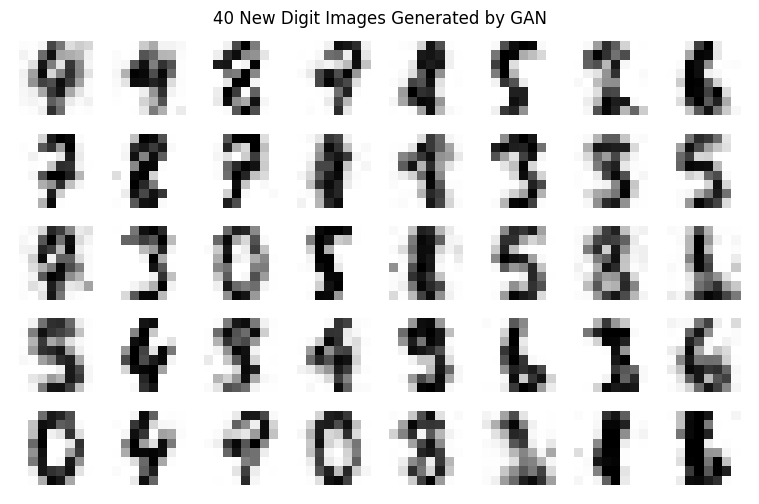


Final D(real) = 0.52
Final D(fake) = 0.41
GAN training completed.


In [ ]:

# PRACTICAL 9(a): GENERATIVE ADVERSARIAL NETWORK (GAN)

import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.datasets import load_digits

# Set random seeds for reproducible results
tf.random.set_seed(0)
np.random.seed(0)

# --------------------------------------------------
# STEP 1: LOAD AND PREPARE REAL DIGIT IMAGES
# --------------------------------------------------

digits = load_digits()

# Pixel values: 0-16, scaled to -1 to +1
real = digits.data.astype("float32") / 16.0
real = real * 2.0 - 1.0

print("Real data shape:", real.shape)
print("Each image contains 64 pixel values.")

LATENT = 32

# --------------------------------------------------
# STEP 2: BUILD THE GENERATOR
# Input: 32 random numbers
# Output: 64 pixel values representing an 8x8 image
# --------------------------------------------------

generator = keras.Sequential([
    keras.Input(shape=(LATENT,)),
    layers.Dense(64, activation="relu"),
    layers.Dense(128, activation="relu"),
    layers.Dense(64, activation="tanh")
], name="generator")

print("\nGENERATOR MODEL")
generator.summary()

# --------------------------------------------------
# STEP 3: BUILD THE DISCRIMINATOR
# Input: image pixels
# Output: probability that image is real
# --------------------------------------------------

discriminator = keras.Sequential([
    keras.Input(shape=(64,)),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(64, activation="relu"),
    layers.Dense(1, activation="sigmoid")
], name="discriminator")

print("\nDISCRIMINATOR MODEL")
discriminator.summary()

# --------------------------------------------------
# STEP 4: LOSS FUNCTION AND OPTIMIZERS
# --------------------------------------------------

bce = keras.losses.BinaryCrossentropy()

g_opt = keras.optimizers.Adam(
    learning_rate=2e-3,
    beta_1=0.5
)

d_opt = keras.optimizers.Adam(
    learning_rate=1e-3,
    beta_1=0.5
)

# --------------------------------------------------
# STEP 5: DEFINE ONE GAN TRAINING STEP
# --------------------------------------------------

@tf.function
def train_step(real_batch):

    n = tf.shape(real_batch)[0]

    # Generate random noise
    z = tf.random.normal((n, LATENT))

    # Train the discriminator
    with tf.GradientTape() as d_tape:

        fake_batch = generator(z, training=True)

        d_real = discriminator(real_batch, training=True)
        d_fake = discriminator(fake_batch, training=True)

        # Real labels are smoothed to 0.9
        d_loss = (
            bce(tf.ones_like(d_real) * 0.9, d_real)
            + bce(tf.zeros_like(d_fake), d_fake)
        )

    d_grads = d_tape.gradient(
        d_loss, discriminator.trainable_variables
    )

    d_opt.apply_gradients(
        zip(d_grads, discriminator.trainable_variables)
    )

    # Train the generator to fool the discriminator
    z = tf.random.normal((n, LATENT))

    with tf.GradientTape() as g_tape:

        fake_batch = generator(z, training=True)
        d_fake = discriminator(fake_batch, training=False)

        # Generator wants fake images to be classified as real
        g_loss = bce(tf.ones_like(d_fake), d_fake)

    g_grads = g_tape.gradient(
        g_loss, generator.trainable_variables
    )

    g_opt.apply_gradients(
        zip(g_grads, generator.trainable_variables)
    )

    return (
        d_loss,
        g_loss,
        tf.reduce_mean(d_real),
        tf.reduce_mean(d_fake)
    )

# --------------------------------------------------
# STEP 6: TRAIN THE GAN
# --------------------------------------------------

dataset = (
    tf.data.Dataset.from_tensor_slices(real)
    .shuffle(1797)
    .batch(64, drop_remainder=True)
    .repeat()
)

fixed_z = tf.random.normal((16, LATENT), seed=1)

snapshots = {}
d_losses = []
g_losses = []

STEPS = 6000

print("\nTraining for", STEPS, "steps...")

for step, batch in zip(range(STEPS + 1), dataset):

    d_l, g_l, dr, df = train_step(batch)

    d_losses.append(float(d_l))
    g_losses.append(float(g_l))

    # Save generated images at selected stages
    if step in (0, 300, 1500, 6000):
        snapshots[step] = generator(
            fixed_z, training=False
        ).numpy()

    if step % 500 == 0:
        print(
            f"Step {step:4d} | "
            f"D loss {float(d_l):.3f} | "
            f"G loss {float(g_l):.3f} | "
            f"D(real) {float(dr):.2f} | "
            f"D(fake) {float(df):.2f}"
        )

# --------------------------------------------------
# STEP 7: DISPLAY REAL AND GENERATED DIGITS
# --------------------------------------------------

fig = plt.figure(figsize=(14, 8))

panels = [
    ("REAL digits", real[:16])
] + [
    (f"Generated at step {s}", snapshots[s])
    for s in sorted(snapshots)
]

for k, (title, imgs) in enumerate(panels):

    ax = fig.add_subplot(2, 3, k + 1)

    # Arrange 16 images in a 4x4 grid
    grid = np.zeros((40, 40))

    for i in range(16):
        r, c = divmod(i, 4)

        grid[
            r * 10 + 1:r * 10 + 9,
            c * 10 + 1:c * 10 + 9
        ] = (imgs[i].reshape(8, 8) + 1) / 2

    ax.imshow(grid, cmap="gray_r", vmin=0, vmax=1)
    ax.set_title(title)
    ax.axis("off")

# Plot loss curves
ax = fig.add_subplot(2, 3, 6)

def smooth(values, window=50):
    return np.convolve(
        values, np.ones(window) / window, mode="valid"
    )

ax.plot(smooth(d_losses), label="Discriminator loss")
ax.plot(smooth(g_losses), label="Generator loss")
ax.set_xlabel("Training step")
ax.set_title("GAN Loss Curves")
ax.legend()

plt.tight_layout()
plt.show()

# --------------------------------------------------
# STEP 8: GENERATE 40 NEW DIGIT IMAGES
# --------------------------------------------------

new_z = tf.random.normal((40, LATENT), seed=99)

new_imgs = generator(new_z, training=False).numpy()

sheet = np.zeros((50, 80))

for i in range(40):
    r, c = divmod(i, 8)

    sheet[
        r * 10 + 1:r * 10 + 9,
        c * 10 + 1:c * 10 + 9
    ] = (new_imgs[i].reshape(8, 8) + 1) / 2

plt.figure(figsize=(10, 6))
plt.imshow(sheet, cmap="gray_r", vmin=0, vmax=1)
plt.axis("off")
plt.title("40 New Digit Images Generated by GAN")
plt.show()

print("\nFinal D(real) =", round(float(dr), 2))
print("Final D(fake) =", round(float(df), 2))
print("GAN training completed.")


In [ ]:
#####INSTALL THIS FOR PRACTICLA 10
!pip install flask joblib scikit-learn requests -q

In [ ]:
############PRACTICAL 10
import joblib
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier

# Load the Iris dataset
iris = load_iris()

X_train, X_test, y_train, y_test = train_test_split(
    iris.data,
    iris.target,
    test_size=0.2,
    random_state=1,
    stratify=iris.target
)

# Create a pipeline: scaling + Random Forest
pipeline = make_pipeline(
    StandardScaler(),
    RandomForestClassifier(n_estimators=100, random_state=0)
)

# Train the model
pipeline.fit(X_train, y_train)

# Check model accuracy
print("Test accuracy of the model to be deployed: %.3f"
      % pipeline.score(X_test, y_test))

# Save model and information needed by the API
bundle = {
    "model": pipeline,
    "feature_names": list(iris.feature_names),
    "class_names": list(iris.target_names)
}

joblib.dump(bundle, "iris_model.joblib")
print("Model saved to iris_model.joblib")

Test accuracy of the model to be deployed: 0.967
Model saved to iris_model.joblib


In [ ]:
import numpy as np
from flask import Flask, request, jsonify

# Create the Flask application
app = Flask(__name__)

# Load the saved model only once
bundle = joblib.load("iris_model.joblib")

model = bundle["model"]
FEATURES = bundle["feature_names"]
CLASSES = bundle["class_names"]


# Validate input data
def validate(row):
    if not isinstance(row, list) or len(row) != len(FEATURES):
        return "Each sample must be a list of 4 numbers: %s" % FEATURES

    if not all(
        isinstance(v, (int, float)) and not isinstance(v, bool)
        for v in row
    ):
        return "All values must be numbers"

    if not all(np.isfinite(v) and 0 <= v <= 20 for v in row):
        return "Values must be finite and between 0 and 20 cm"

    return None


# Home endpoint
@app.route("/")
def home():
    return jsonify(
        message="Iris prediction API",
        endpoints=["/health", "/predict", "/predict_batch"]
    )


# Health-check endpoint
@app.route("/health")
def health():
    return jsonify(
        status="ok",
        model="RandomForest iris classifier"
    )


# Predict one flower
@app.route("/predict", methods=["POST"])
def predict():
    data = request.get_json(silent=True)

    if data is None or "features" not in data:
        return jsonify(
            error='Send JSON like {"features": [5.1, 3.5, 1.4, 0.2]}'
        ), 400

    problem = validate(data["features"])

    if problem:
        return jsonify(error=problem), 400

    x = np.array(data["features"], dtype=float).reshape(1, -1)
    probabilities = model.predict_proba(x)[0]
    index = int(np.argmax(probabilities))

    return jsonify(
        prediction=CLASSES[index],
        confidence=round(float(probabilities[index]), 4),
        probabilities={
            name: round(float(prob), 4)
            for name, prob in zip(CLASSES, probabilities)
        }
    )


# Predict multiple flowers
@app.route("/predict_batch", methods=["POST"])
def predict_batch():
    data = request.get_json(silent=True)

    if (
        data is None
        or "samples" not in data
        or not isinstance(data["samples"], list)
        or not data["samples"]
    ):
        return jsonify(
            error='Send JSON with a non-empty "samples" list'
        ), 400

    for i, row in enumerate(data["samples"]):
        problem = validate(row)
        if problem:
            return jsonify(error=f"Sample {i}: {problem}"), 400

    predictions = model.predict(
        np.array(data["samples"], dtype=float)
    )

    return jsonify(
        predictions=[CLASSES[int(p)] for p in predictions],
        count=len(predictions)
    )


print("Flask API created successfully!")

Flask API created successfully!


In [ ]:
# Create a test client
client = app.test_client()

# Test 1: Home endpoint
print("1) GET /")
r = client.get("/")
print("Status:", r.status_code, "| Reply:", r.json)

# Test 2: Health endpoint
print("\n2) GET /health")
r = client.get("/health")
print("Status:", r.status_code, "| Reply:", r.json)

# Test 3: Predict a setosa-like flower
print("\n3) POST /predict - Setosa-like flower")
r = client.post("/predict", json={
    "features": [5.1, 3.5, 1.4, 0.2]
})
print("Status:", r.status_code, "| Reply:", r.json)

# Test 4: Predict a virginica-like flower
print("\n4) POST /predict - Virginica-like flower")
r = client.post("/predict", json={
    "features": [6.7, 3.0, 5.2, 2.3]
})
print("Status:", r.status_code, "| Reply:", r.json)

# Test 5: Batch prediction for three flowers
print("\n5) POST /predict_batch")
r = client.post("/predict_batch", json={
    "samples": [
        [5.0, 3.4, 1.5, 0.2],
        [6.0, 2.9, 4.5, 1.5],
        [7.2, 3.0, 5.8, 1.6]
    ]
})
print("Status:", r.status_code, "| Reply:", r.json)

# Test 6: Invalid input - only three values
print("\n6) Invalid input - only three values")
r = client.post("/predict", json={
    "features": [5.1, 3.5, 1.4]
})
print("Status:", r.status_code, "| Reply:", r.json)

# Test 7: Invalid input - text instead of numbers
print("\n7) Invalid input - text values")
r = client.post("/predict", json={
    "features": ["a", "b", "c", "d"]
})
print("Status:", r.status_code, "| Reply:", r.json)

# Test 8: Invalid input - absurd measurement
print("\n8) Invalid input - value above 20 cm")
r = client.post("/predict", json={
    "features": [5.1, 500, 1.4, 0.2]
})
print("Status:", r.status_code, "| Reply:", r.json)

1) GET /
Status: 200 | Reply: {'endpoints': ['/health', '/predict', '/predict_batch'], 'message': 'Iris prediction API'}

2) GET /health
Status: 200 | Reply: {'model': 'RandomForest iris classifier', 'status': 'ok'}

3) POST /predict - Setosa-like flower
Status: 200 | Reply: {'confidence': 1.0, 'prediction': 'setosa', 'probabilities': {'setosa': 1.0, 'versicolor': 0.0, 'virginica': 0.0}}

4) POST /predict - Virginica-like flower
Status: 200 | Reply: {'confidence': 0.99, 'prediction': 'virginica', 'probabilities': {'setosa': 0.0, 'versicolor': 0.01, 'virginica': 0.99}}

5) POST /predict_batch
Status: 200 | Reply: {'count': 3, 'predictions': ['setosa', 'versicolor', 'virginica']}

6) Invalid input - only three values
Status: 400 | Reply: {'error': "Each sample must be a list of 4 numbers: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']"}

7) Invalid input - text values
Status: 400 | Reply: {'error': 'All values must be numbers'}

8) Invalid input - valu